# MorphoNup — train and evaluate one dataset

Set the dataset, number of outer folds and seeds below, then run all cells.

* `RUN_MODE = "background"` (recommended): starts `scripts/run_cv.py` detached (`setsid nohup`). It keeps running if the notebook or the session closes. Re-run the *Progress* and *Results* cells any time.
* `RUN_MODE = "inline"`: trains inside this kernel (the kernel must stay alive for the whole run).
* `RUN_MODE = "results_only"`: no training; shows what is saved.

Every run writes its figures automatically (per fold, per seed, over seeds); the Results cells only display them and redraw any that are missing from the saved files. Finished folds are skipped, so relaunching resumes a stopped job.

In [1]:
DATASET = "DatasetNup_1/Homo_sapiens"   # one of the 12 IDs printed by the next cell
K_FOLDS = 5                              # 5 or 10
SEEDS = [151000, 152000, 153000]          # the reported seeds (config.SEEDS)
RUN_MODE = "results_only"                # "background" | "inline" | "results_only"
ALLOW_BUSY_GPU = False                   # shared account: True only after checking with labmates
SHOW_SEED = SEEDS[0]                     # seed whose per-seed figures are shown below

In [2]:
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
_null, _err = os.open(os.devnull, os.O_WRONLY), os.dup(2)
os.dup2(_null, 2)                                    # TensorFlow's CUDA start-up lines go to C-level stderr
try:
    import tensorflow  # noqa: F401
finally:
    os.dup2(_err, 2)
    os.close(_null)
    os.close(_err)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "morphonup" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display

from morphonup import config, figures, jobs
from morphonup.cv import run_dir

pd.set_option("display.width", 200, "display.max_columns", 40)


def show(path, width=900):
    """Display a saved figure with its caption (from the folder's figure_catalog.csv)."""
    path = Path(path)
    if not path.exists():
        print("missing:", path.relative_to(ROOT))
        return
    cat = path.parent / "figure_catalog.csv"
    caption = pd.read_csv(cat).set_index("png").suggested_caption.get(path.name, "") if cat.exists() else ""
    display(Markdown(f"**{path.stem}** — `{path.relative_to(ROOT)}`  \n{caption}"))
    display(Image(filename=str(path), width=width))

assert DATASET in config.DATASETS, "\n".join(config.DATASETS)
assert RUN_MODE in ("background", "inline", "results_only"), RUN_MODE
RUN = run_dir(DATASET, K_FOLDS)
fasta = next((config.dataset_folder(DATASET) / "sequence").glob("*.fas"))
headers = [l[1:].strip() for l in fasta.open() if l.startswith(">")]
n, pos = len(headers), sum(h.startswith("nucleosomal_sequence") for h in headers)
print(f"{DATASET}: {n:,} sequences, {pos:,} nucleosomal ({pos / n:.1%}), {n - pos:,} linker")
print(f"outer {K_FOLDS}-fold: ~{n // K_FOLDS:,} test sequences per fold; results -> {RUN.relative_to(ROOT)}")
gpu, procs = jobs.gpu_status()
print("GPU:", gpu)
print("GPU processes:", procs or "none")
print("MorphoNup jobs running:", jobs.running_jobs() or "none")

DatasetNup_1/Homo_sapiens: 4,573 sequences, 2,273 nucleosomal (49.7%), 2,300 linker
outer 5-fold: ~914 test sequences per fold; results -> results/DatasetNup_1/Homo_sapiens/k5/full
GPU: NVIDIA GeForce RTX 4070 Ti, 0 %, 1 MiB, 12282 MiB
GPU processes: none
MorphoNup jobs running: none


## Train

In [3]:
if RUN_MODE == "background":
    LOG = jobs.launch(DATASET, K_FOLDS, SEEDS, allow_busy_gpu=ALLOW_BUSY_GPU)
    print("launched; log:", LOG.relative_to(ROOT))
elif RUN_MODE == "inline":
    gpu, procs = jobs.gpu_status()
    if procs and not ALLOW_BUSY_GPU:
        raise RuntimeError("GPU in use: " + "; ".join(procs))
    import tensorflow as tf
    from morphonup.cv import run
    from morphonup.data import Dataset
    ds = Dataset(config.dataset_folder(DATASET))
    for device in tf.config.list_physical_devices("GPU"):
        tf.config.set_logical_device_configuration(
            device, [tf.config.LogicalDeviceConfiguration(memory_limit=config.gpu_memory_mb(len(ds.y)))])
    run(ds, DATASET, K_FOLDS, SEEDS)
else:
    print("results_only: no training started")

results_only: no training started


## Progress

In [4]:
display(jobs.progress(DATASET, K_FOLDS, SEEDS))
print(jobs.tail(jobs.log_path(DATASET, K_FOLDS, SEEDS)))

,dataset,k,arm,seed,base_folds_done,base_pooled,refit_folds_done,refit_pooled,status
0,DatasetNup_1/Homo_sapiens,5,full,151000,5,True,5,True,done
1,DatasetNup_1/Homo_sapiens,5,full,152000,5,True,5,True,done
2,DatasetNup_1/Homo_sapiens,5,full,153000,5,True,5,True,done


(no log yet)


## Results

Pooled out-of-fold results over the outer test folds. **Refit** (trained on fit + tune rows) is the reported model; **base** (fit rows only, checkpoint chosen on tune rows) is shown for comparison.

In [5]:
drawn = figures.ensure_figures(RUN, config.SETTINGS["epochs"]) if RUN.exists() else []
print(f"{len(drawn)} figures drawn now (missing or refreshed)")
summary = RUN / "summary" / "summary.md"
display(Markdown(summary.read_text()) if summary.exists() else Markdown("_No finished seed yet._"))

2 figures drawn now (missing or refreshed)


# DatasetNup_1/Homo_sapiens, k5, arm `full`: pooled out-of-fold metrics over seeds

## Base (fit rows) — 3 seed(s)

| Metric | Mean ± SD | Min | Max | Best seed |
|---|---|---|---|---|
| Correct test sequences | 4048.0 ± 14.7 | 4031.0 | 4057.0 | 153000 |
| Accuracy | 0.8852 ± 0.0032 | 0.8815 | 0.8872 | 153000 |
| Balanced accuracy | 0.8853 ± 0.0032 | 0.8816 | 0.8873 | 153000 |
| Sensitivity | 0.9072 ± 0.0019 | 0.9050 | 0.9085 | 151000 |
| Specificity | 0.8635 ± 0.0045 | 0.8583 | 0.8665 | 153000 |
| Precision | 0.8679 ± 0.0040 | 0.8632 | 0.8705 | 153000 |
| F1 | 0.8871 ± 0.0030 | 0.8836 | 0.8889 | 153000 |
| MCC | 0.7712 ± 0.0064 | 0.7639 | 0.7751 | 153000 |
| Cohen's kappa | 0.7704 ± 0.0064 | 0.7630 | 0.7744 | 153000 |
| ROC AUC | 0.9456 ± 0.0006 | 0.9449 | 0.9460 | 152000 |
| PR AUC | 0.9394 ± 0.0007 | 0.9390 | 0.9402 | 152000 |
| Log loss | 0.2940 ± 0.0010 | 0.2932 | 0.2952 | 153000 |
| Brier score | 0.0863 ± 0.0003 | 0.0859 | 0.0865 | 153000 |
| ECE | 0.0162 ± 0.0022 | 0.0145 | 0.0187 | 153000 |
| Train − test accuracy gap | 0.0954 ± 0.0046 | 0.0903 | 0.0993 | 151000 |

## Refit (fit + tune rows; reported) — 3 seed(s)

| Metric | Mean ± SD | Min | Max | Best seed |
|---|---|---|---|---|
| Correct test sequences | 4074.7 ± 1.2 | 4074.0 | 4076.0 | 151000 |
| Accuracy | 0.8910 ± 0.0003 | 0.8909 | 0.8913 | 151000 |
| Balanced accuracy | 0.8912 ± 0.0003 | 0.8910 | 0.8915 | 151000 |
| Sensitivity | 0.9126 ± 0.0024 | 0.9103 | 0.9151 | 151000 |
| Specificity | 0.8697 ± 0.0020 | 0.8678 | 0.8717 | 152000 |
| Precision | 0.8738 ± 0.0014 | 0.8725 | 0.8752 | 152000 |
| F1 | 0.8928 ± 0.0005 | 0.8924 | 0.8933 | 151000 |
| MCC | 0.7829 ± 0.0006 | 0.7824 | 0.7836 | 151000 |
| Cohen's kappa | 0.7821 ± 0.0005 | 0.7818 | 0.7827 | 151000 |
| ROC AUC | 0.9467 ± 0.0005 | 0.9462 | 0.9471 | 151000 |
| PR AUC | 0.9414 ± 0.0006 | 0.9408 | 0.9420 | 151000 |
| Log loss | 0.2902 ± 0.0011 | 0.2892 | 0.2913 | 153000 |
| Brier score | 0.0848 ± 0.0003 | 0.0845 | 0.0851 | 153000 |
| ECE | 0.0131 ± 0.0008 | 0.0123 | 0.0139 | 153000 |
| Train − test accuracy gap | 0.0883 ± 0.0040 | 0.0842 | 0.0922 | 151000 |


### Over seeds

**seed_metrics** — `results/DatasetNup_1/Homo_sapiens/k5/full/summary/figures/seed_metrics.png`  
Pooled out-of-fold metrics of each seed (dots) and their mean (bar), k=5; seeds 151000, 152000, 153000.

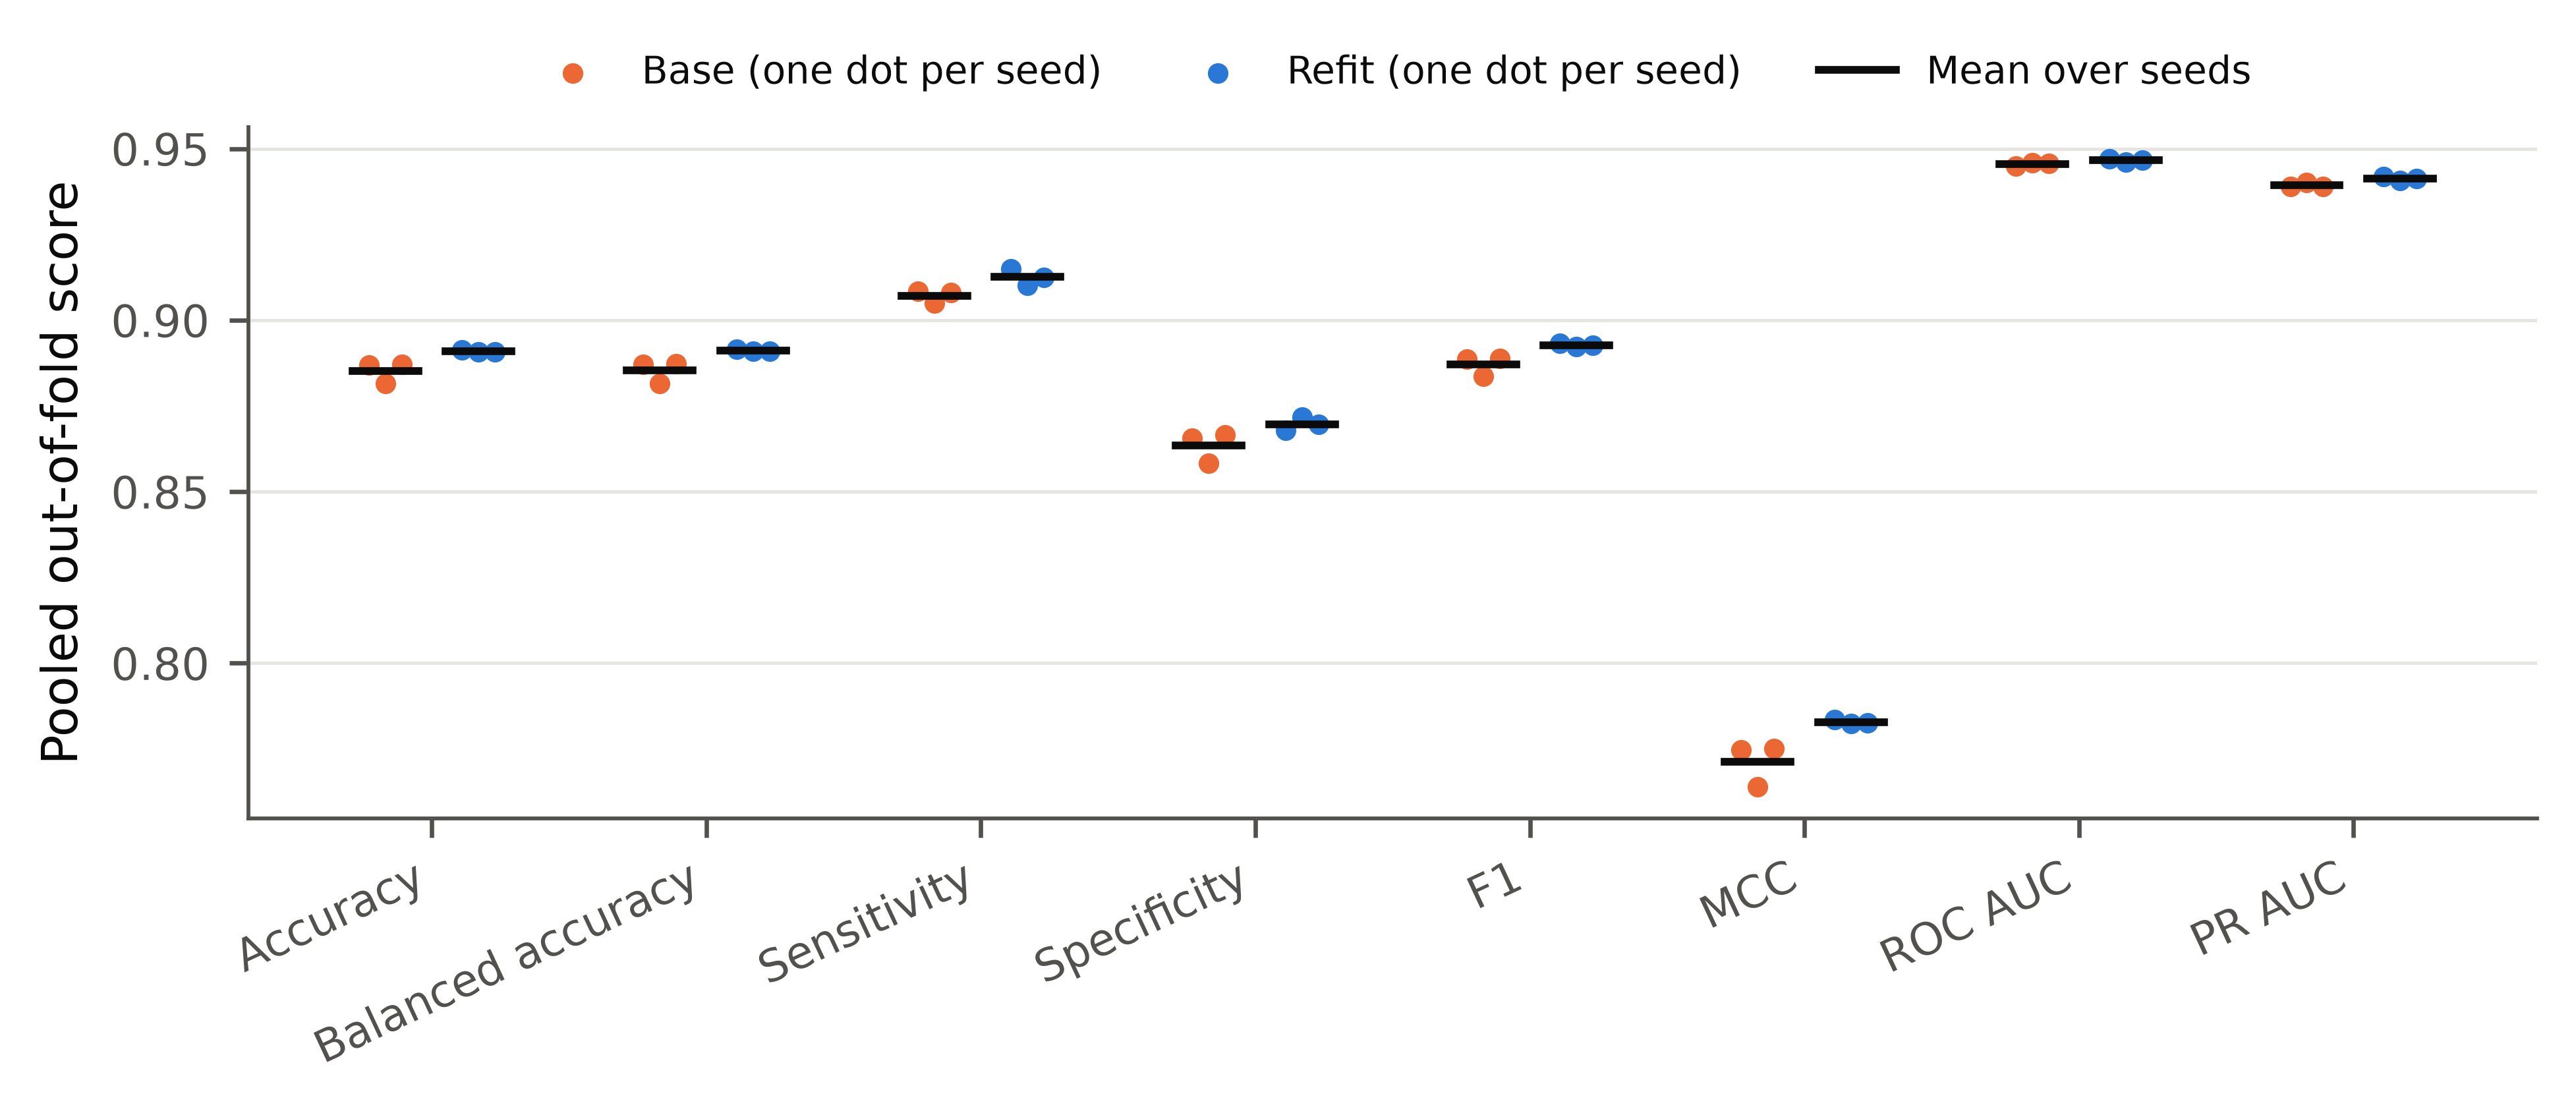

**roc_pr_seeds** — `results/DatasetNup_1/Homo_sapiens/k5/full/summary/figures/roc_pr_seeds.png`  
Pooled out-of-fold ROC and precision-recall curves, one line per seed, k=5.

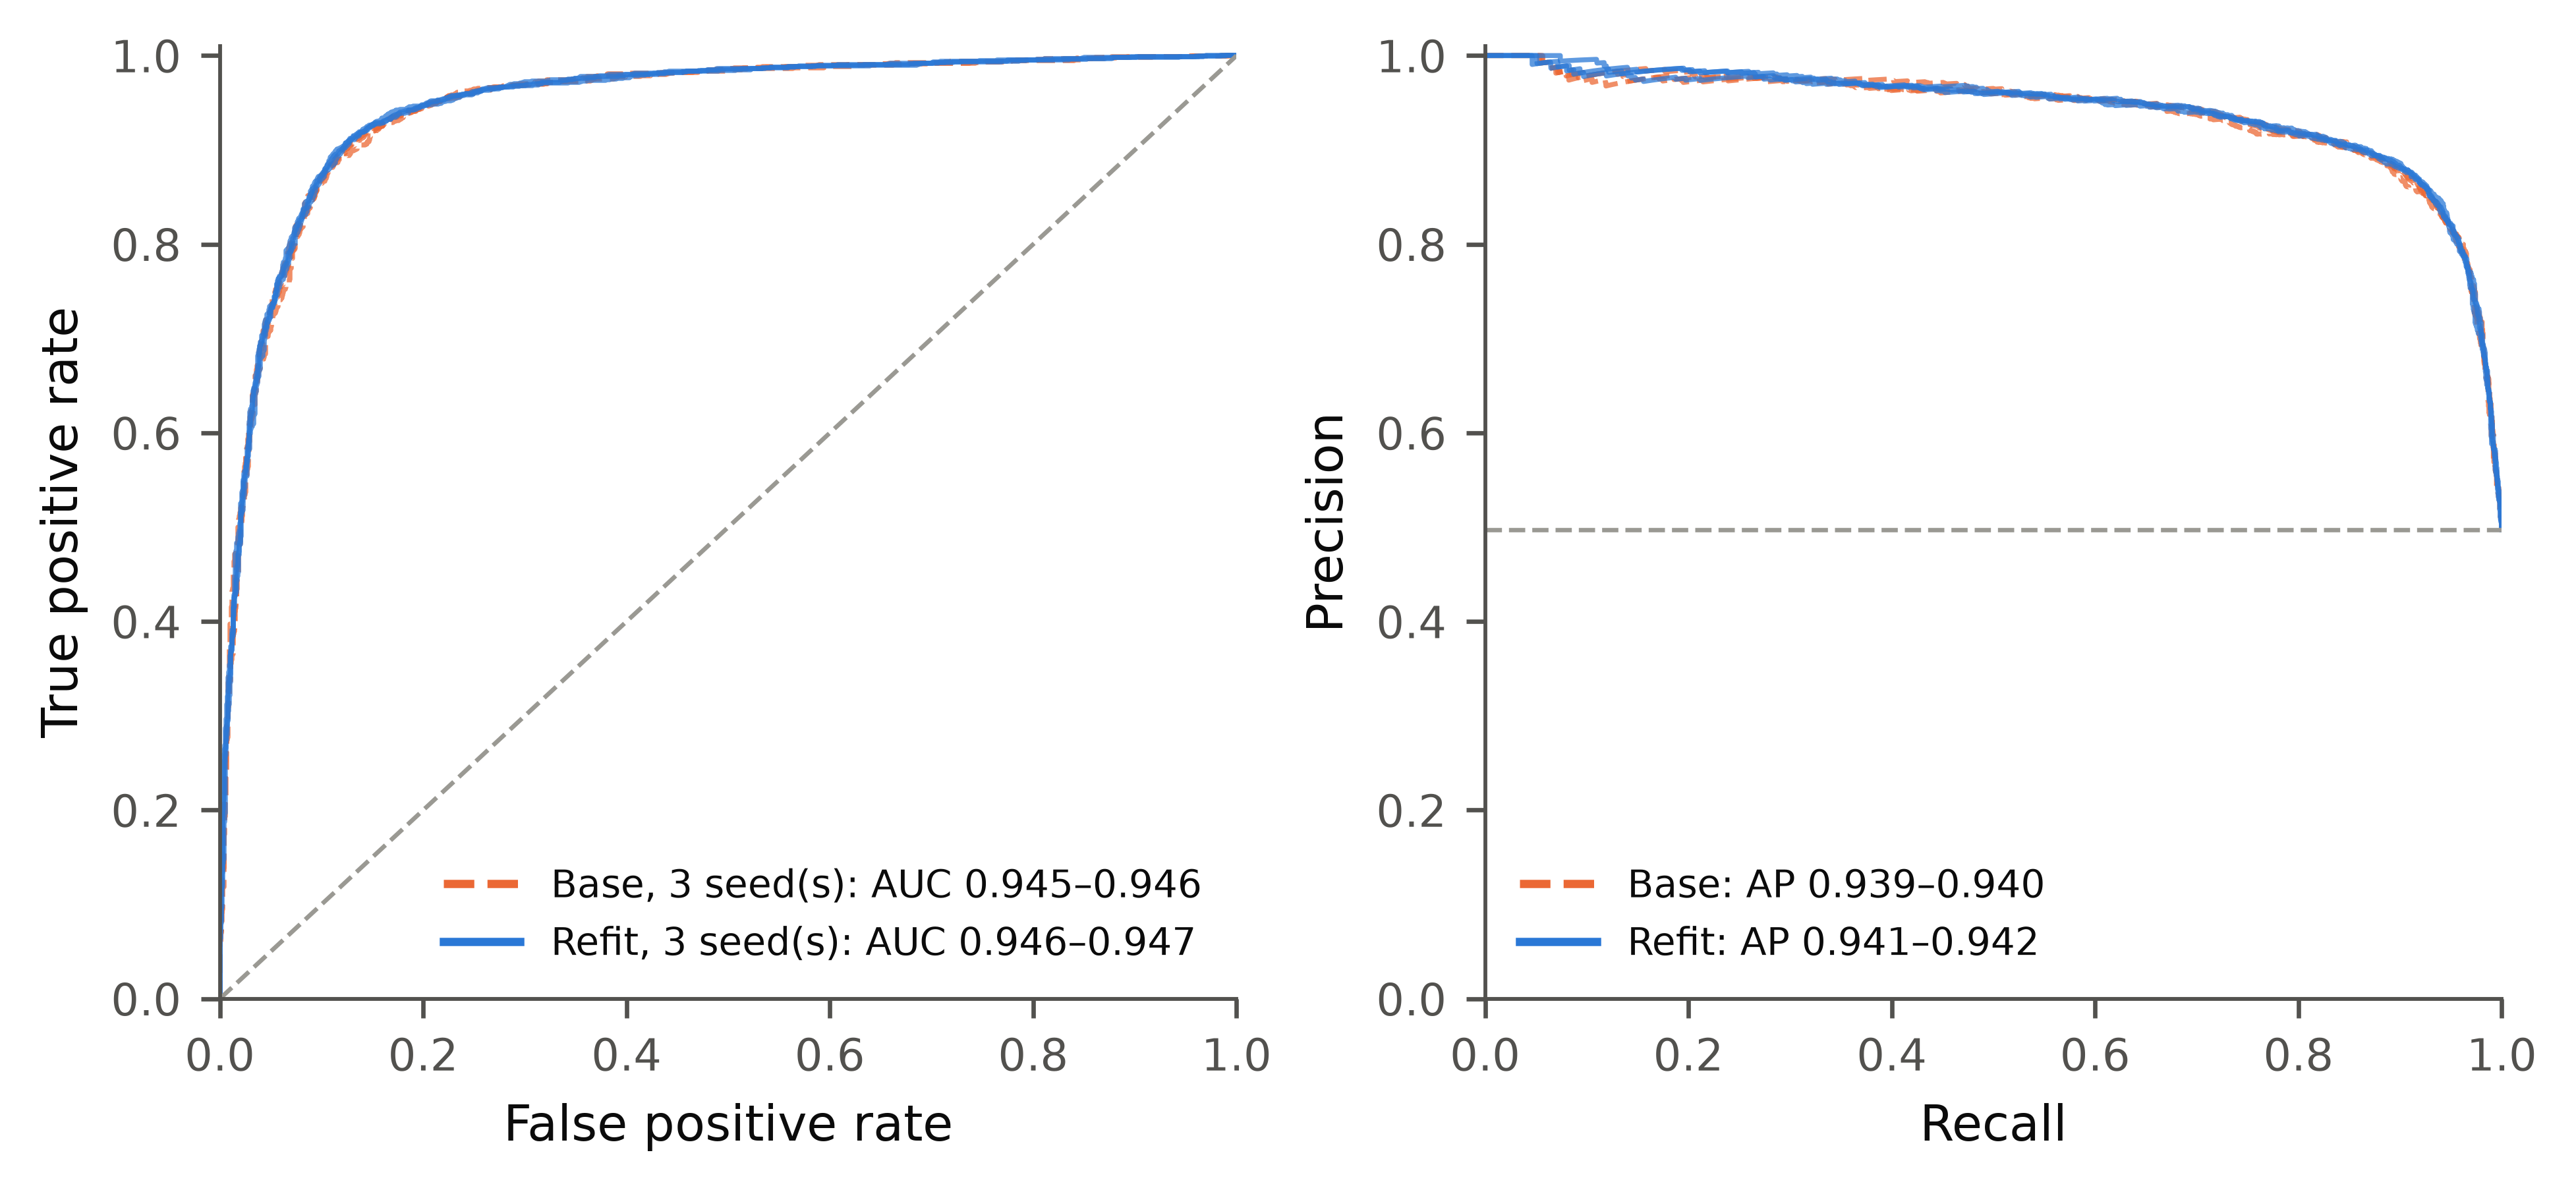

In [6]:
for name in ("seed_metrics", "roc_pr_seeds"):
    show(RUN / "summary" / "figures" / f"{name}.png")

### One seed (`SHOW_SEED`): reported model (refit)

**roc_pr** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/refit/figures/roc_pr.png`  
Refit (fit + tune rows; reported): ROC and precision-recall curves of the pooled out-of-fold predictions (k=5, n=4,573). Dashed: chance (ROC) and nucleosome prevalence 0.497 (PR).

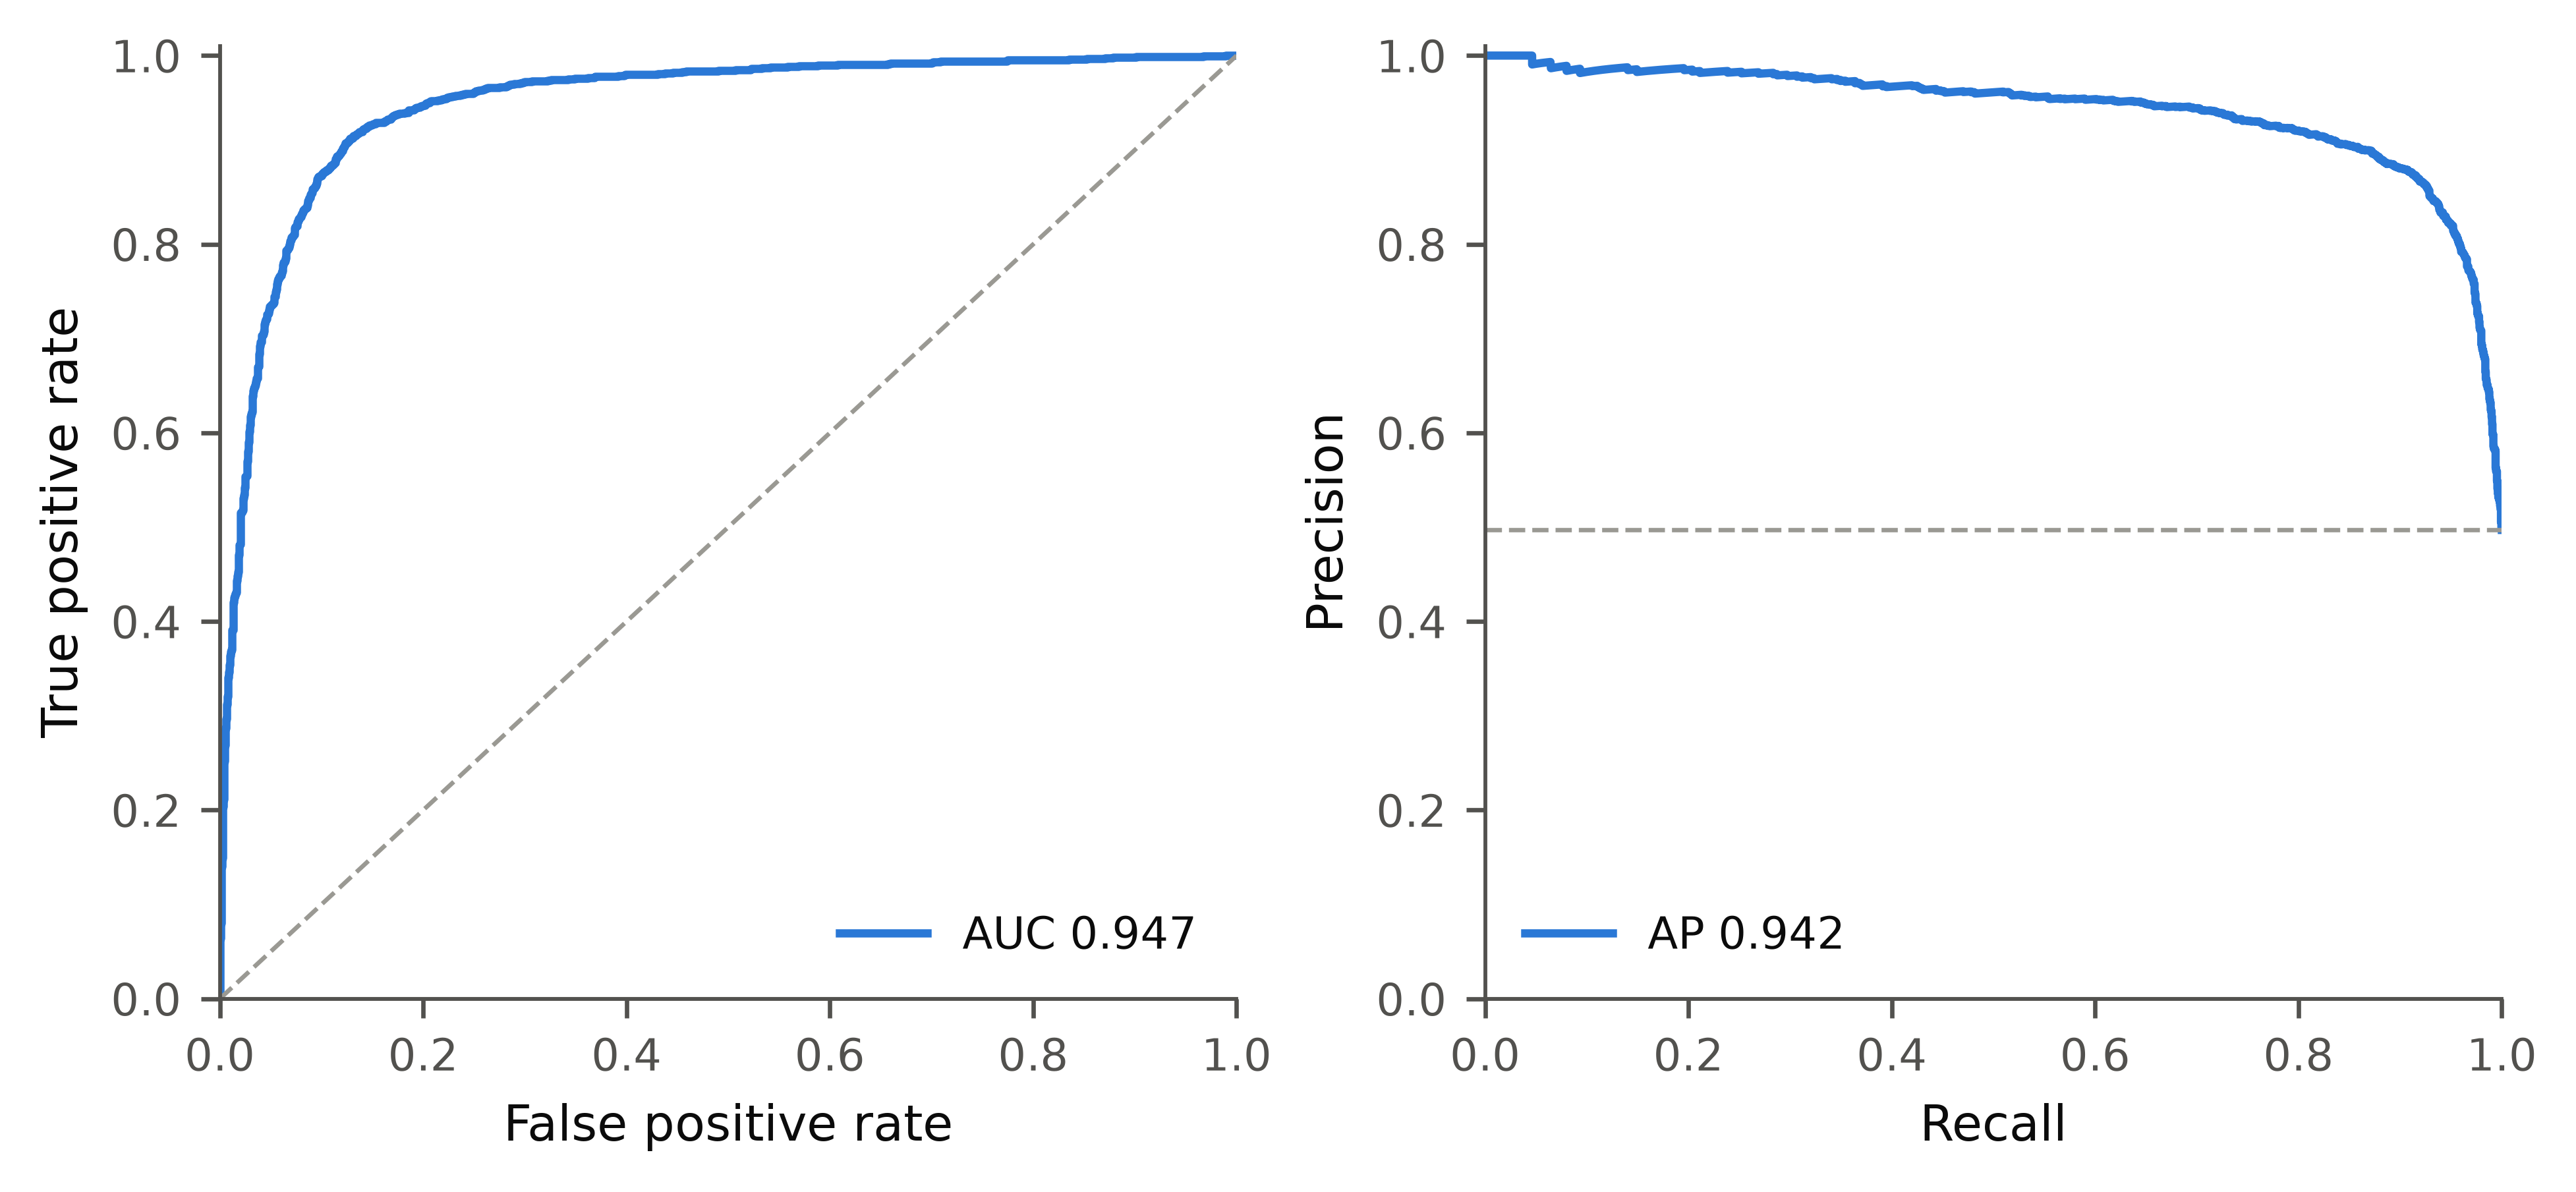

**confusion_matrix** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/refit/figures/confusion_matrix.png`  
Refit (fit + tune rows; reported): pooled confusion matrix over the 5 outer test folds at threshold 0.5; accuracy 0.8913 (4,076/4,573), MCC 0.7836.

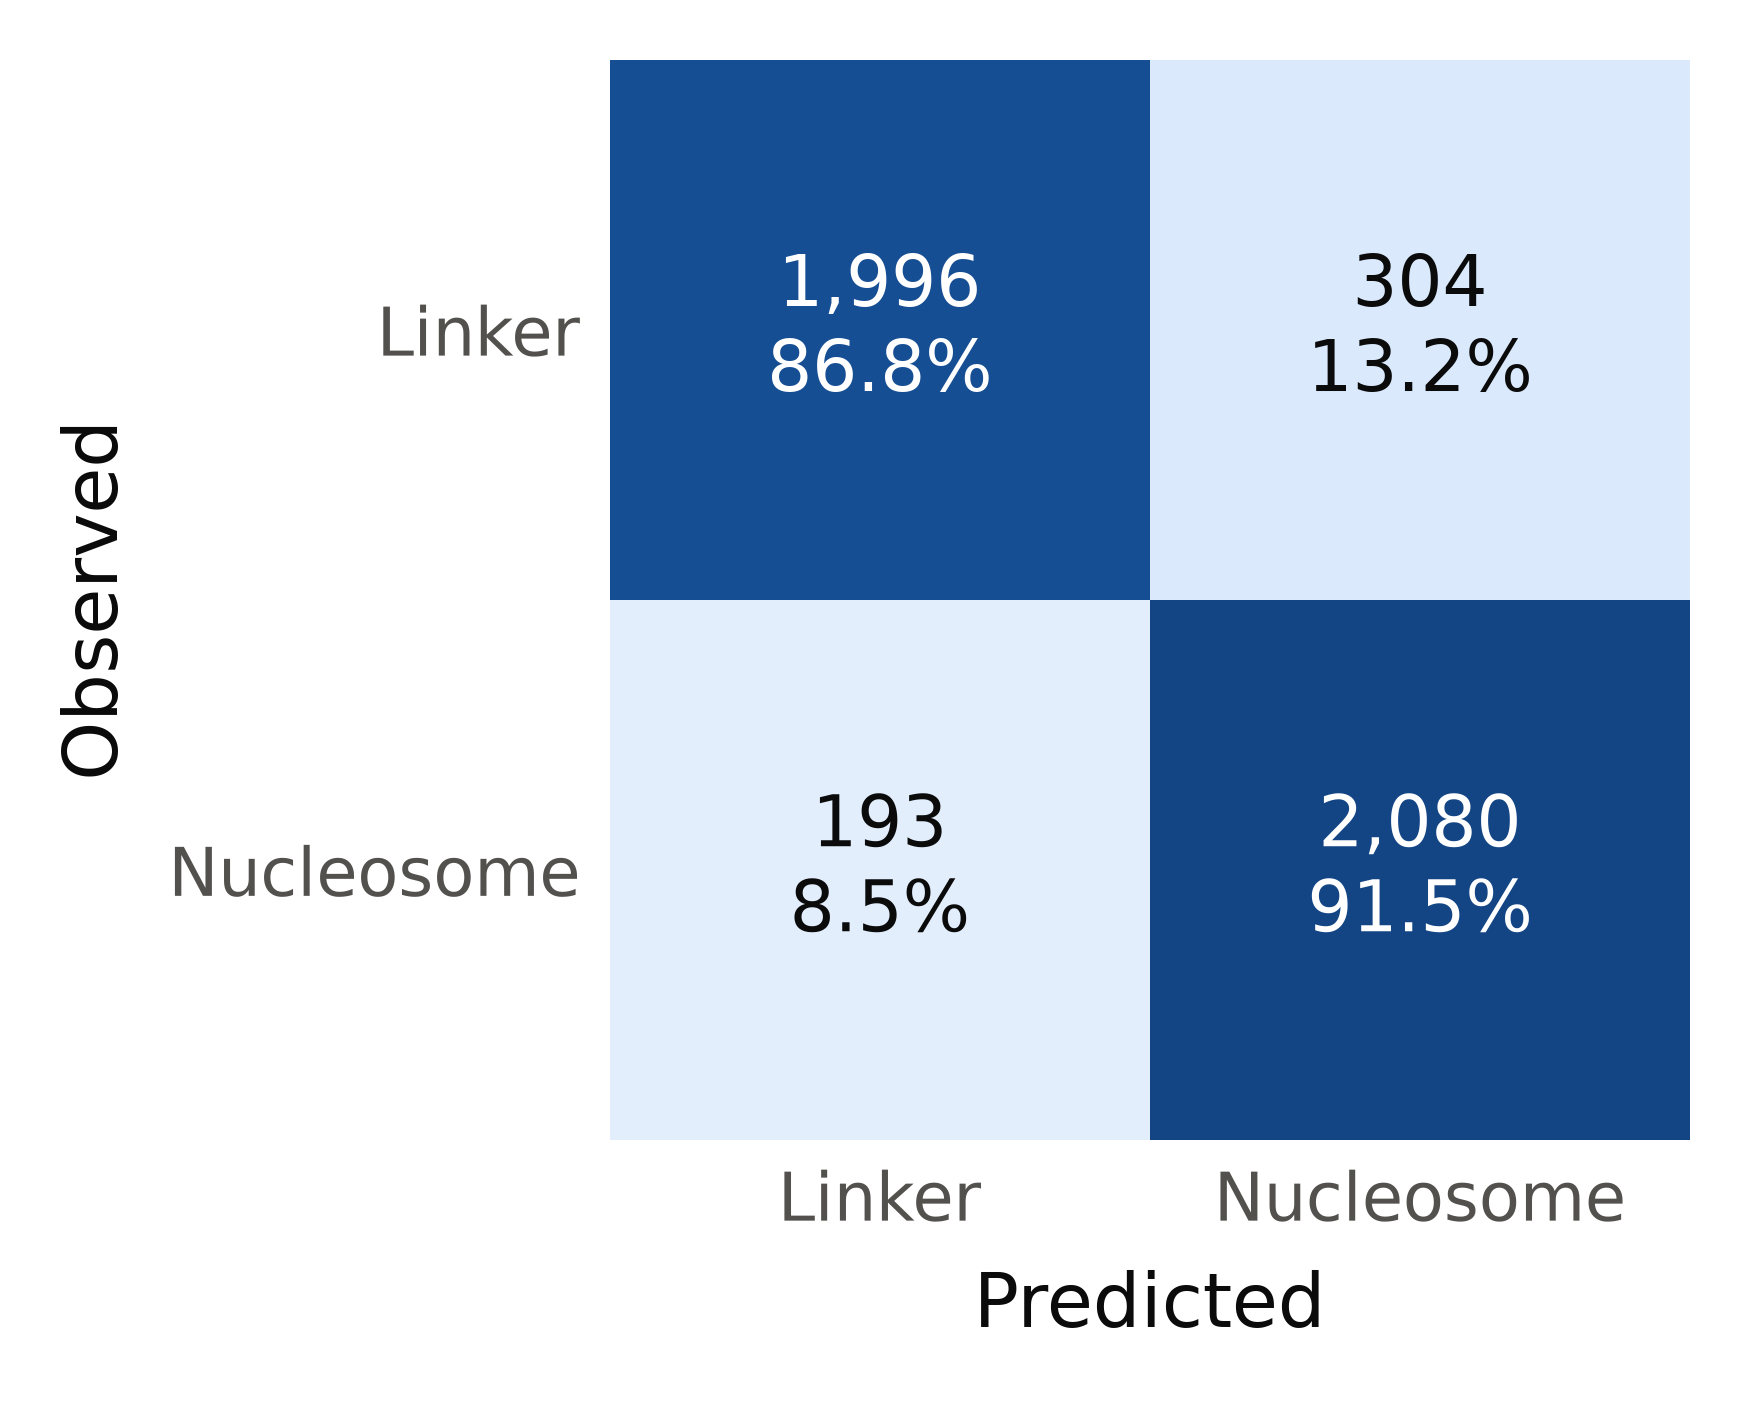

**reliability** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/refit/figures/reliability.png`  
Refit (fit + tune rows; reported): reliability (10 equal-width bins, empty bins omitted) and predicted-probability distributions by observed class; dotted line: decision threshold 0.5.

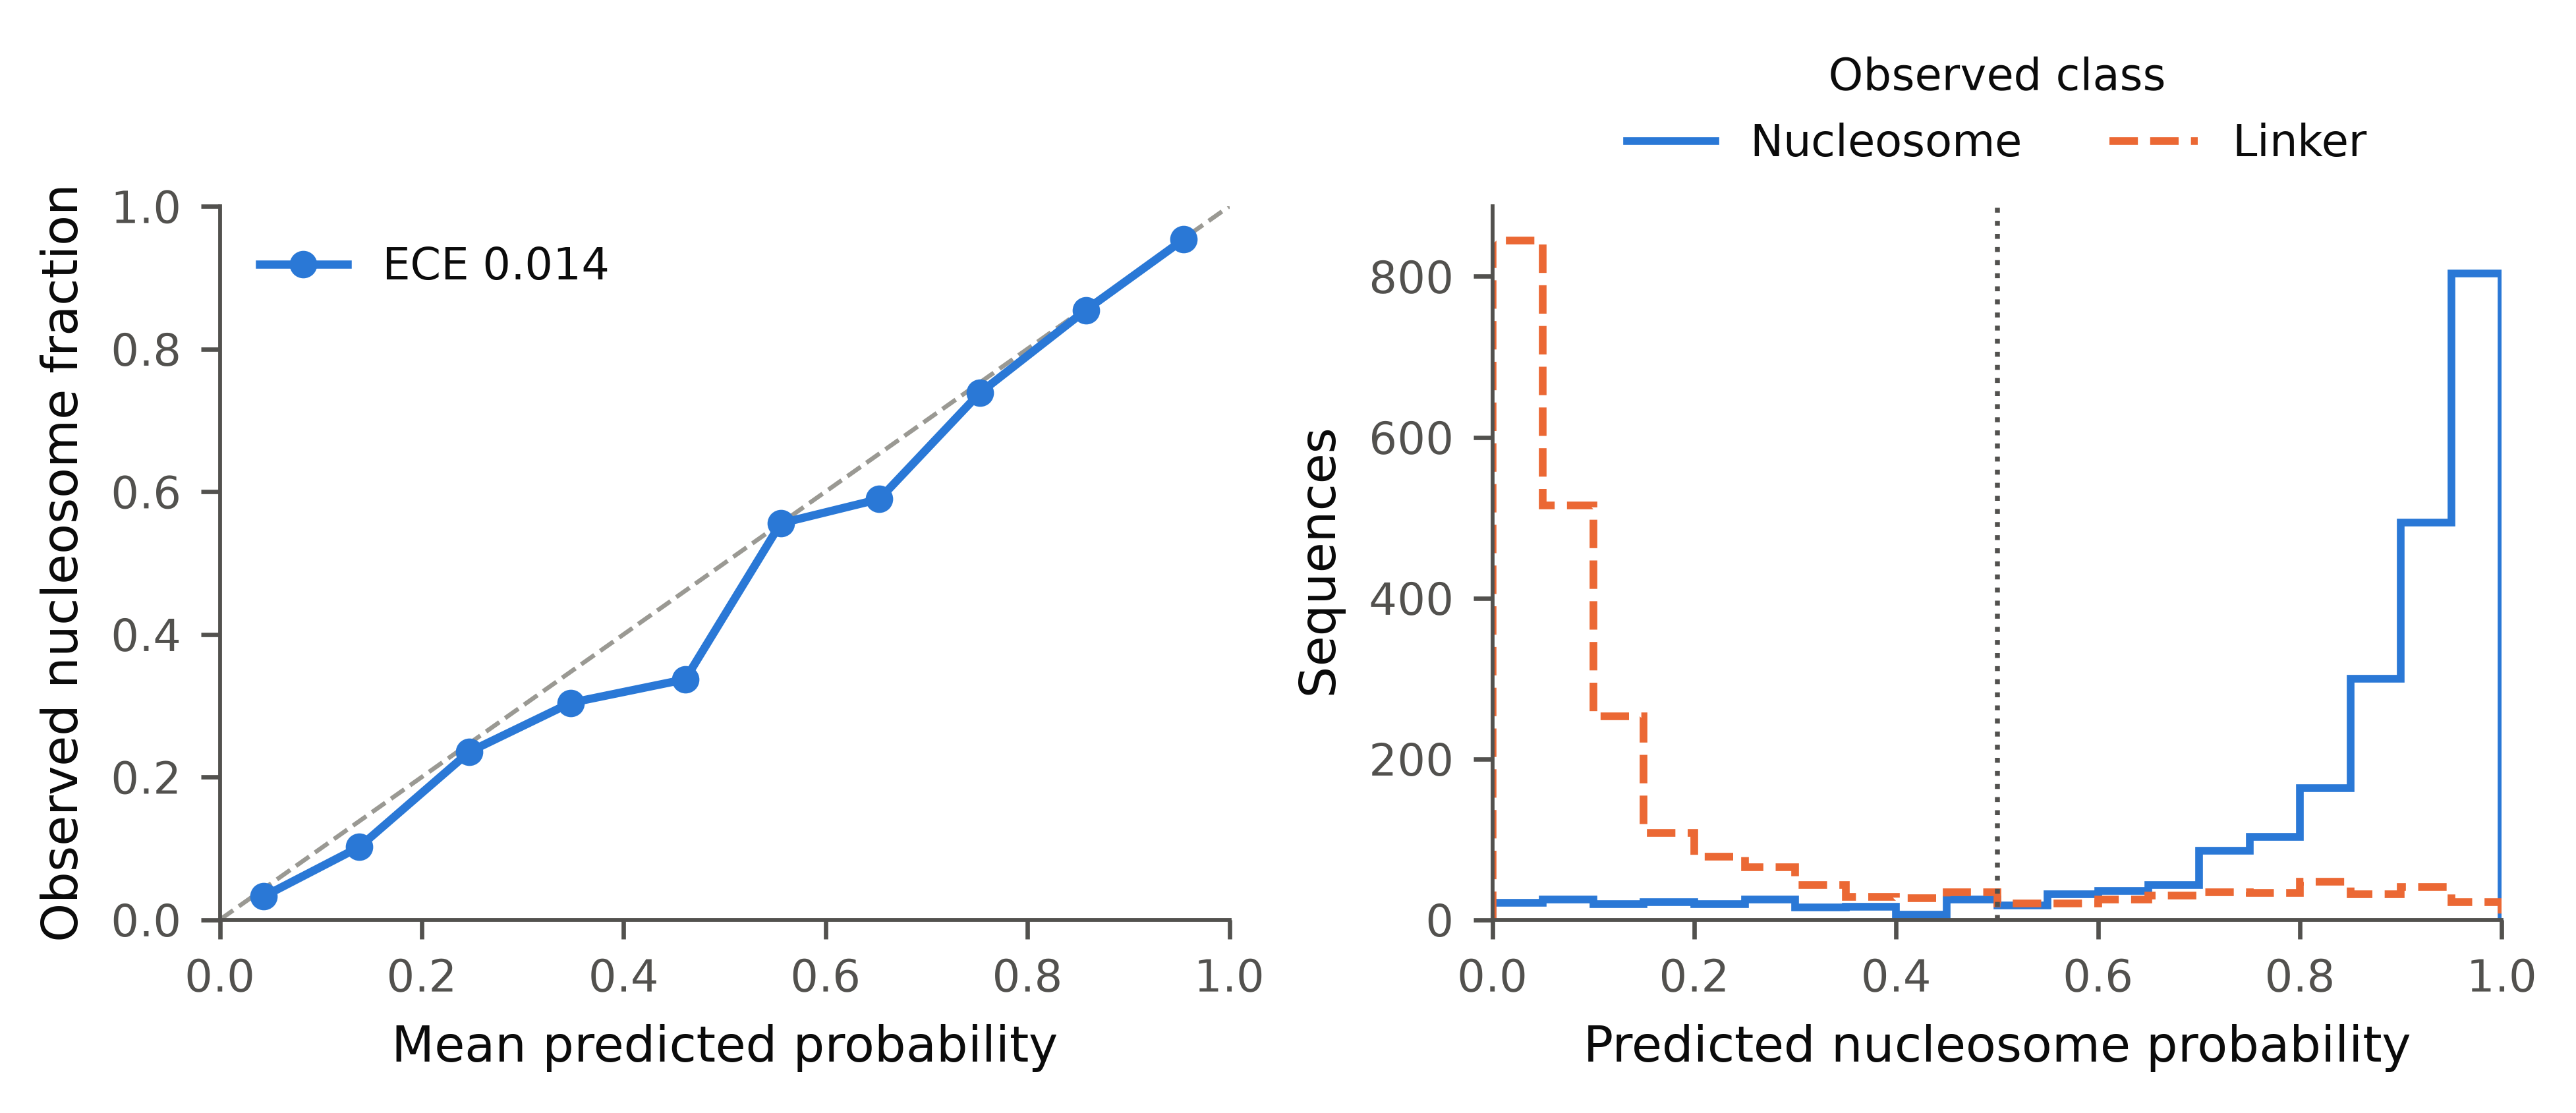

**fold_metrics** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/refit/figures/fold_metrics.png`  
Refit (fit + tune rows; reported): metric of each outer test fold (dots) and of the pooled out-of-fold predictions (bar), k=5. Folds share training rows, so their spread is descriptive, not an independent-sample interval.

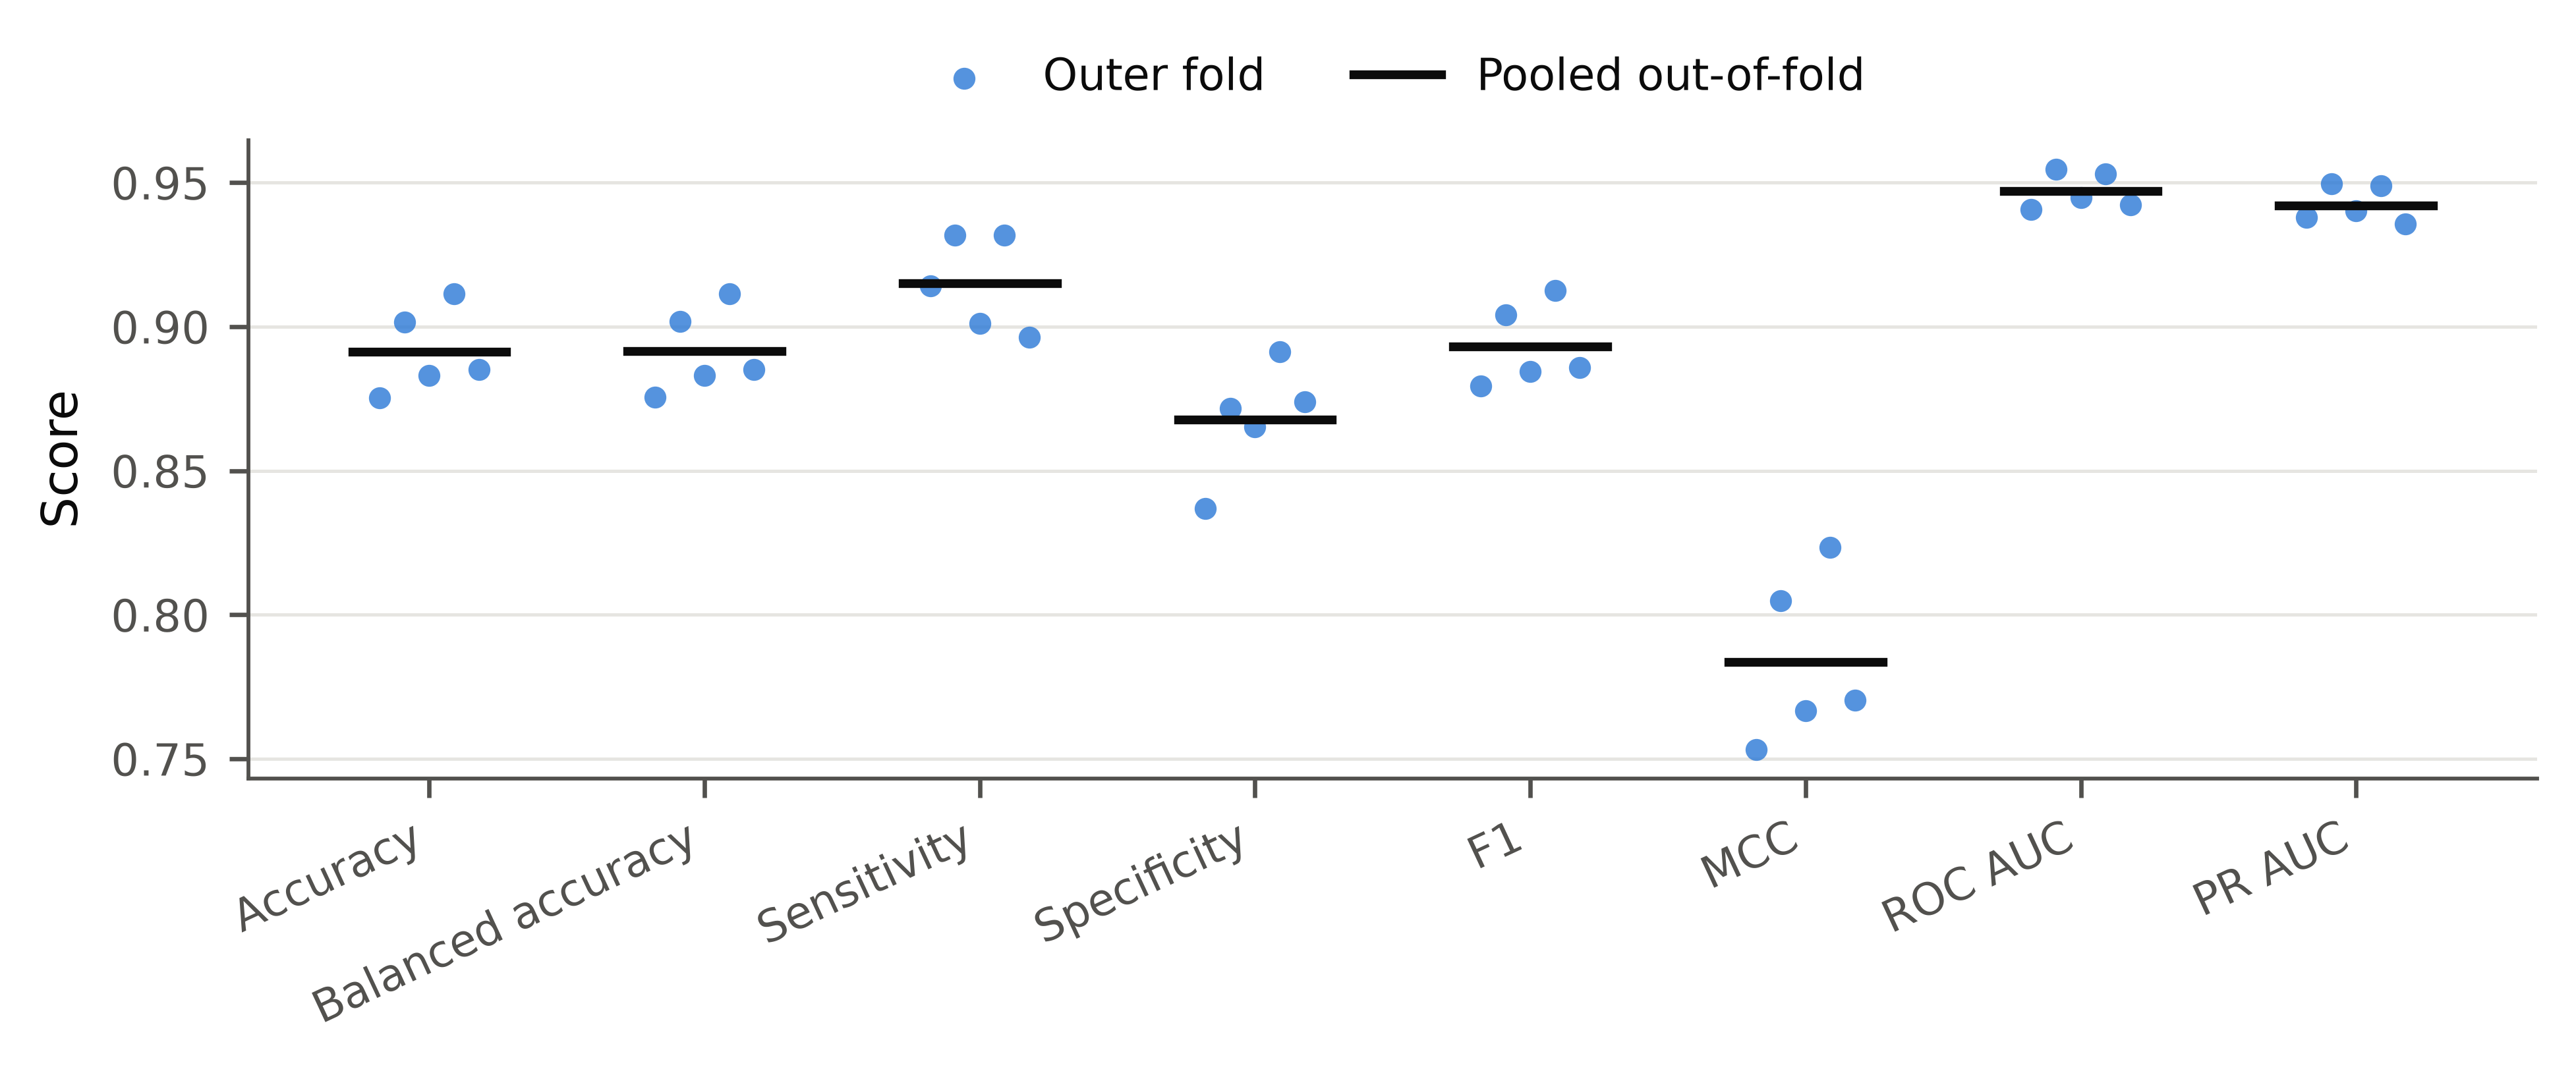

**generalization_gap** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/refit/figures/generalization_gap.png`  
Refit (fit + tune rows; reported): accuracy of the selected network on its training rows, the tune rows and the outer test rows of each fold (dropout off). Mean training-minus-test gap 8.4 pp.

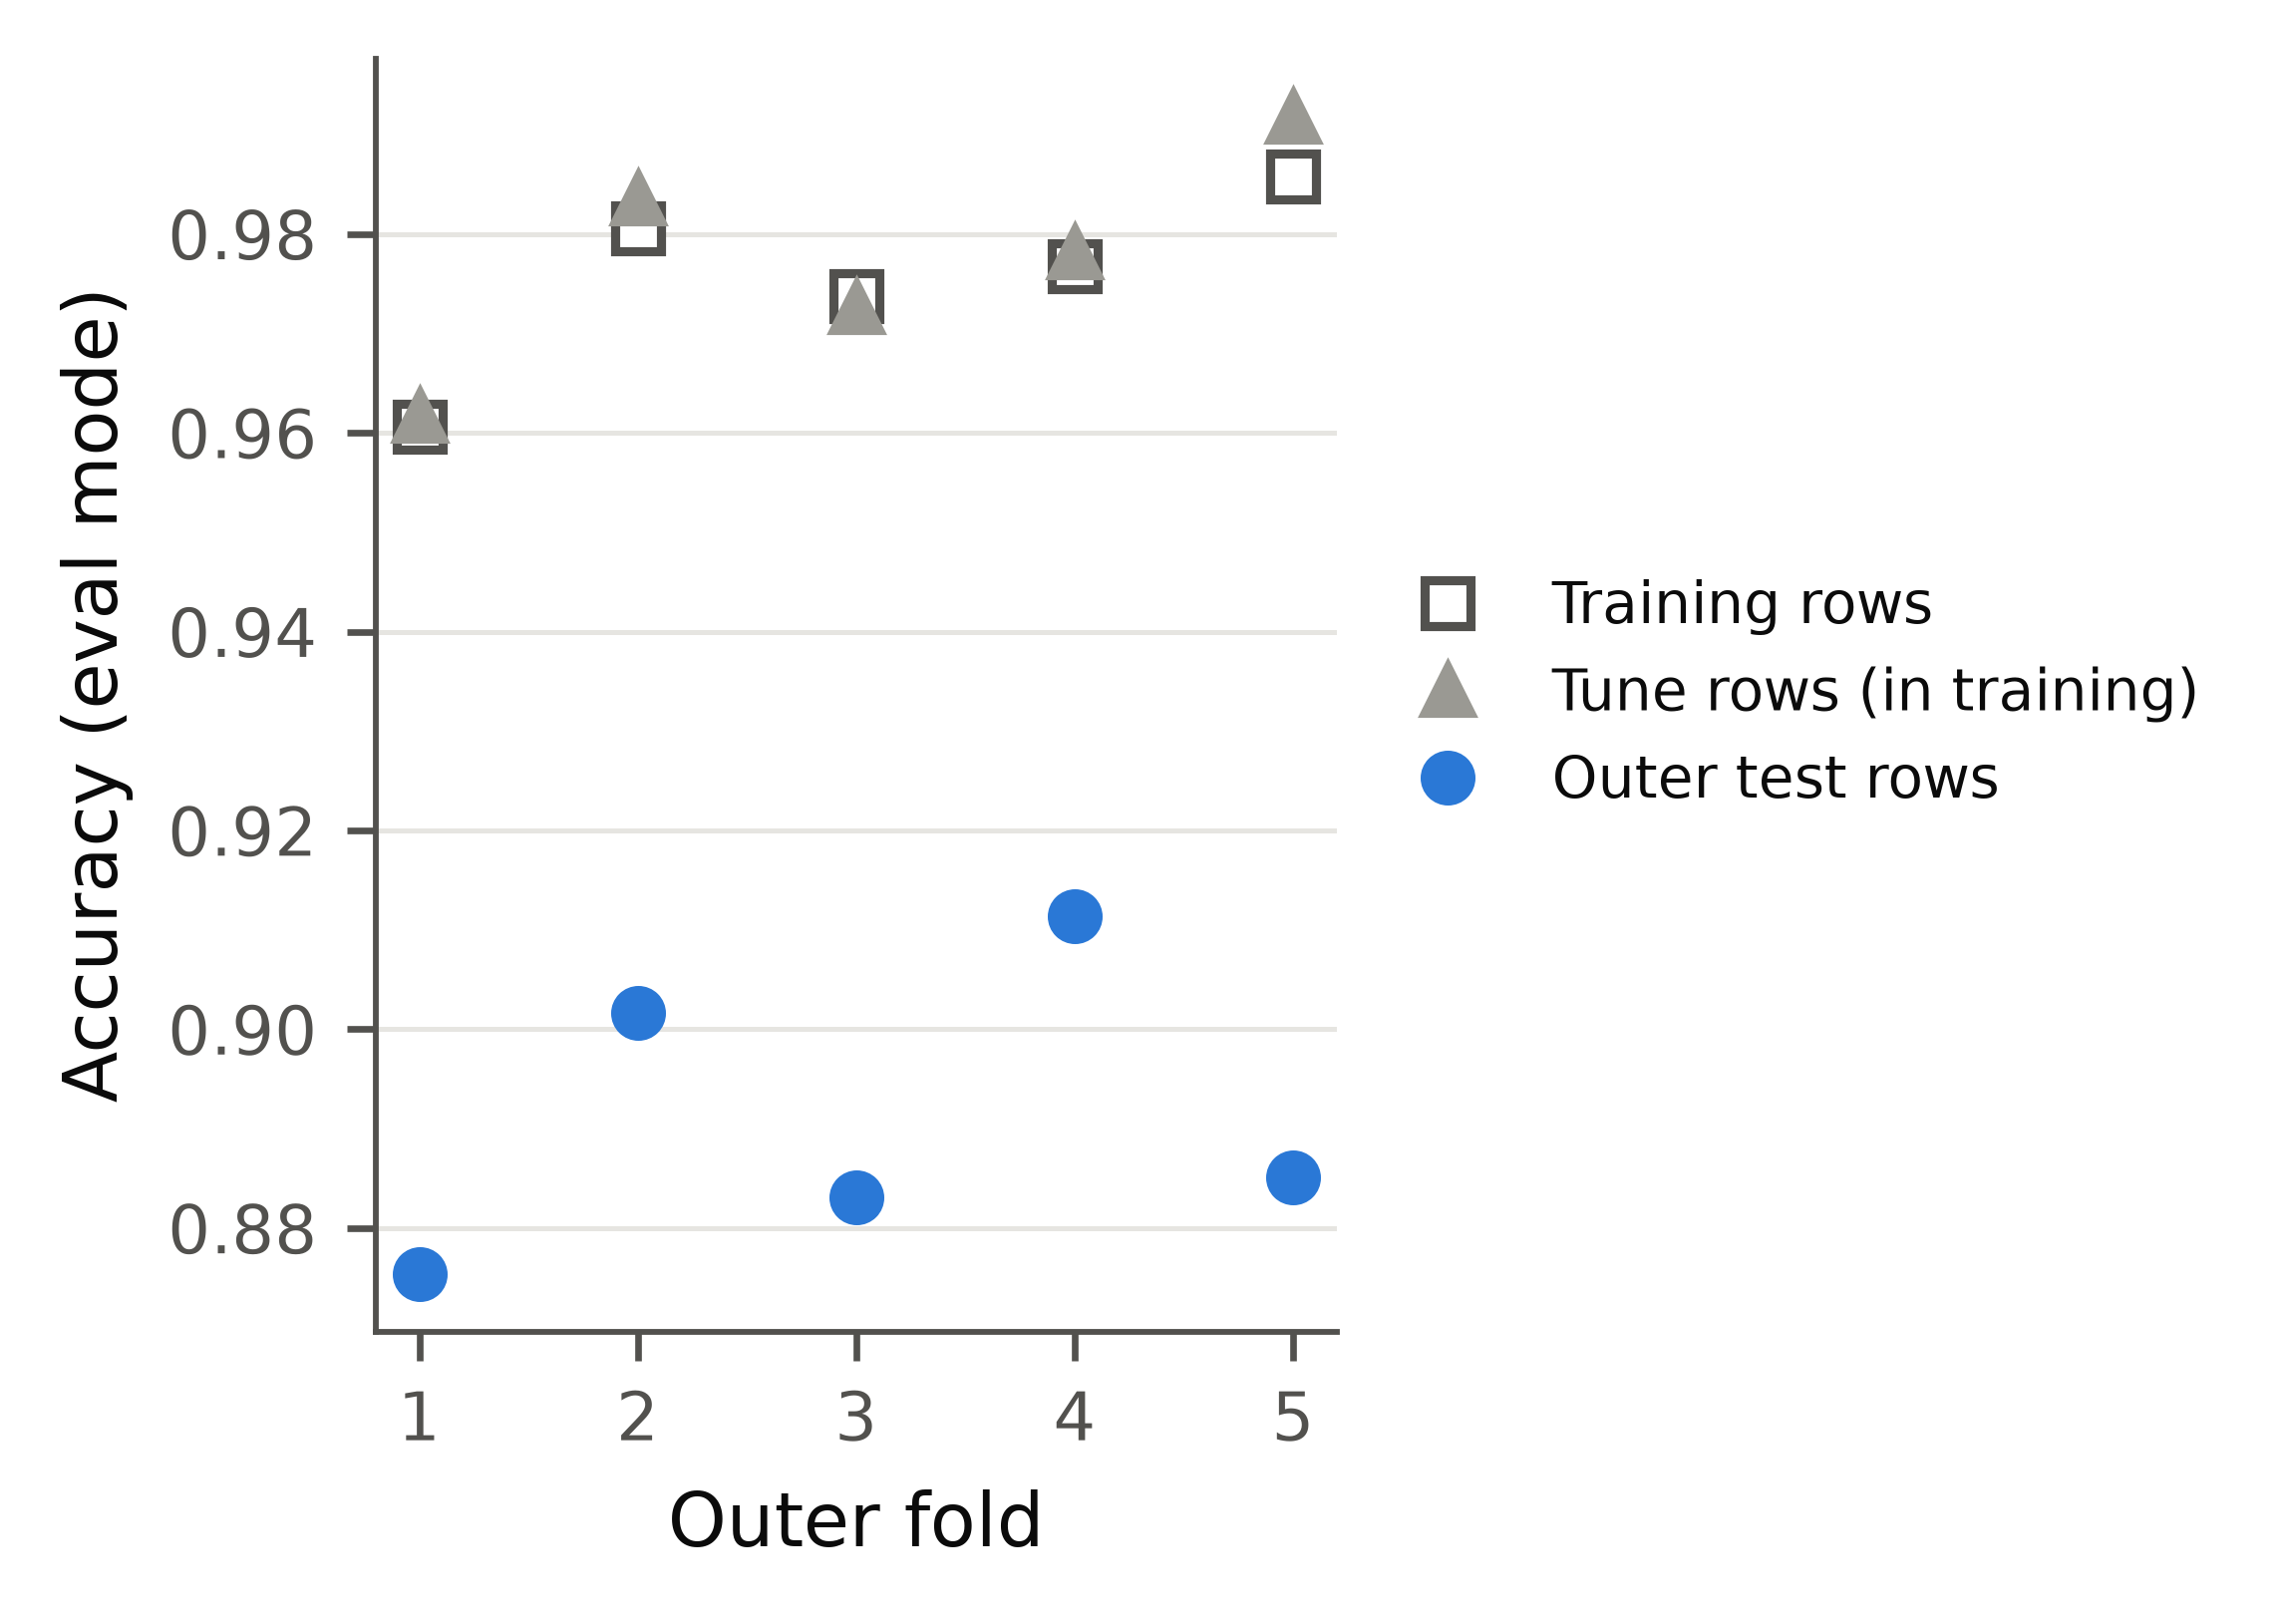

In [7]:
POOLED = RUN / f"seed_{SHOW_SEED}" / "pooled"
for name in ("roc_pr", "confusion_matrix", "reliability", "fold_metrics", "generalization_gap"):
    show(POOLED / "refit" / "figures" / f"{name}.png")

### One seed: base vs refit, and training

**roc_pr_base_vs_refit** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/figures/roc_pr_base_vs_refit.png`  
Pooled out-of-fold ROC and precision-recall curves of the base run and the refit (reported) of each fold, k=5, same test rows.

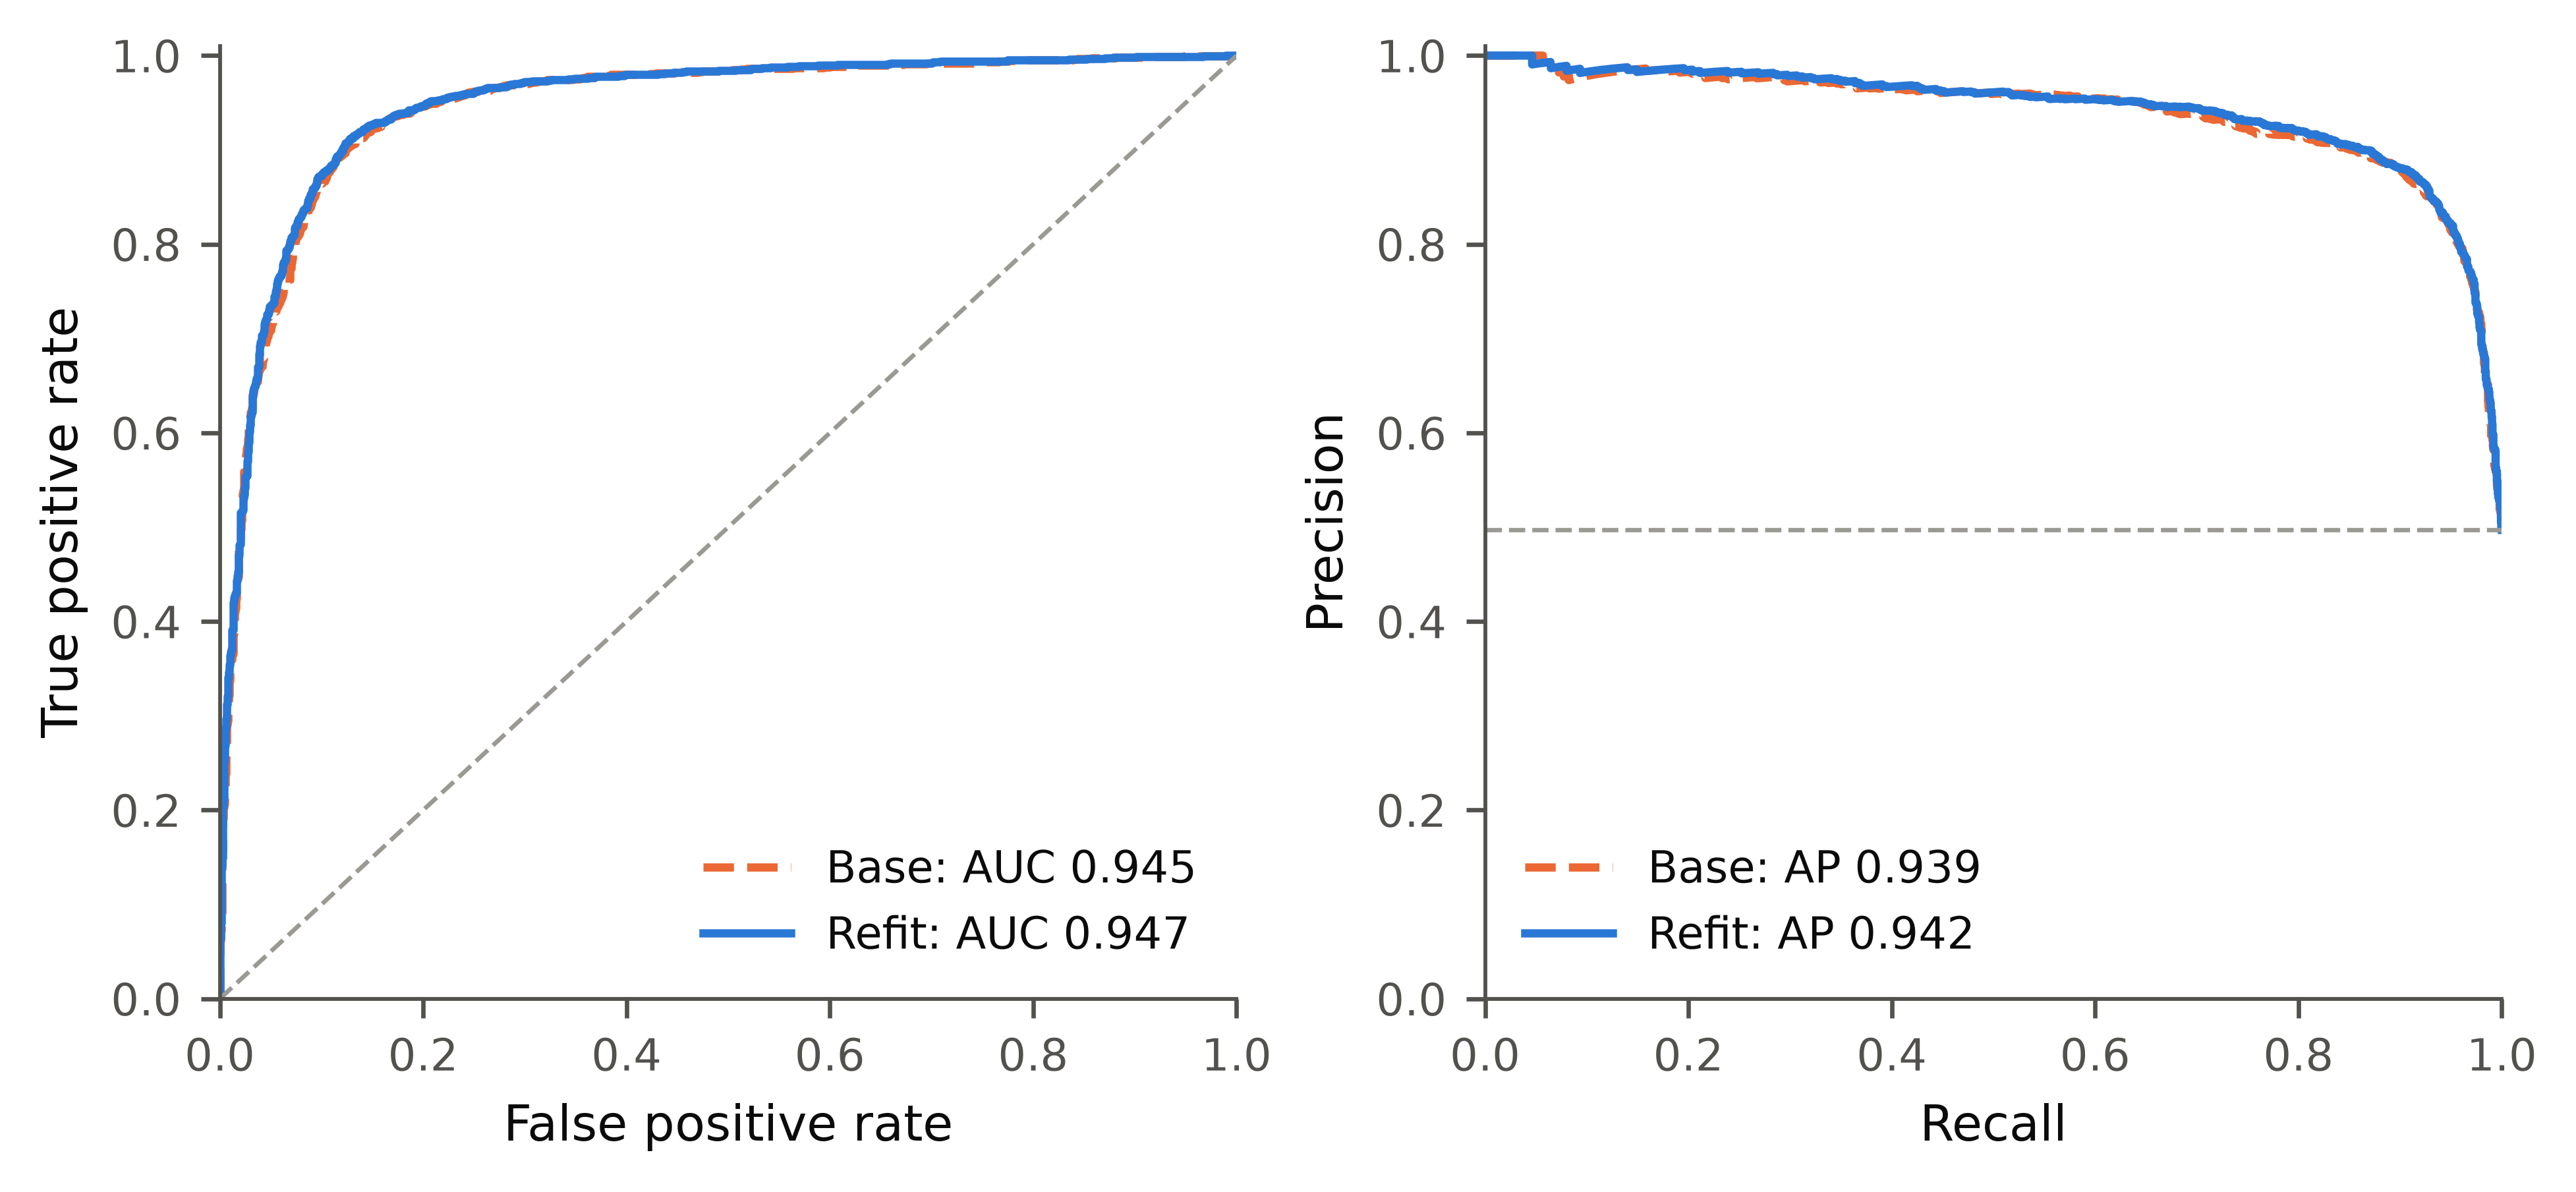

**fold_accuracy_base_vs_refit** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/figures/fold_accuracy_base_vs_refit.png`  
Test accuracy of each outer fold (lines pair the same fold) for the base run and its refit, k=5; bars: pooled. Refit minus base: +20 correct sequences.

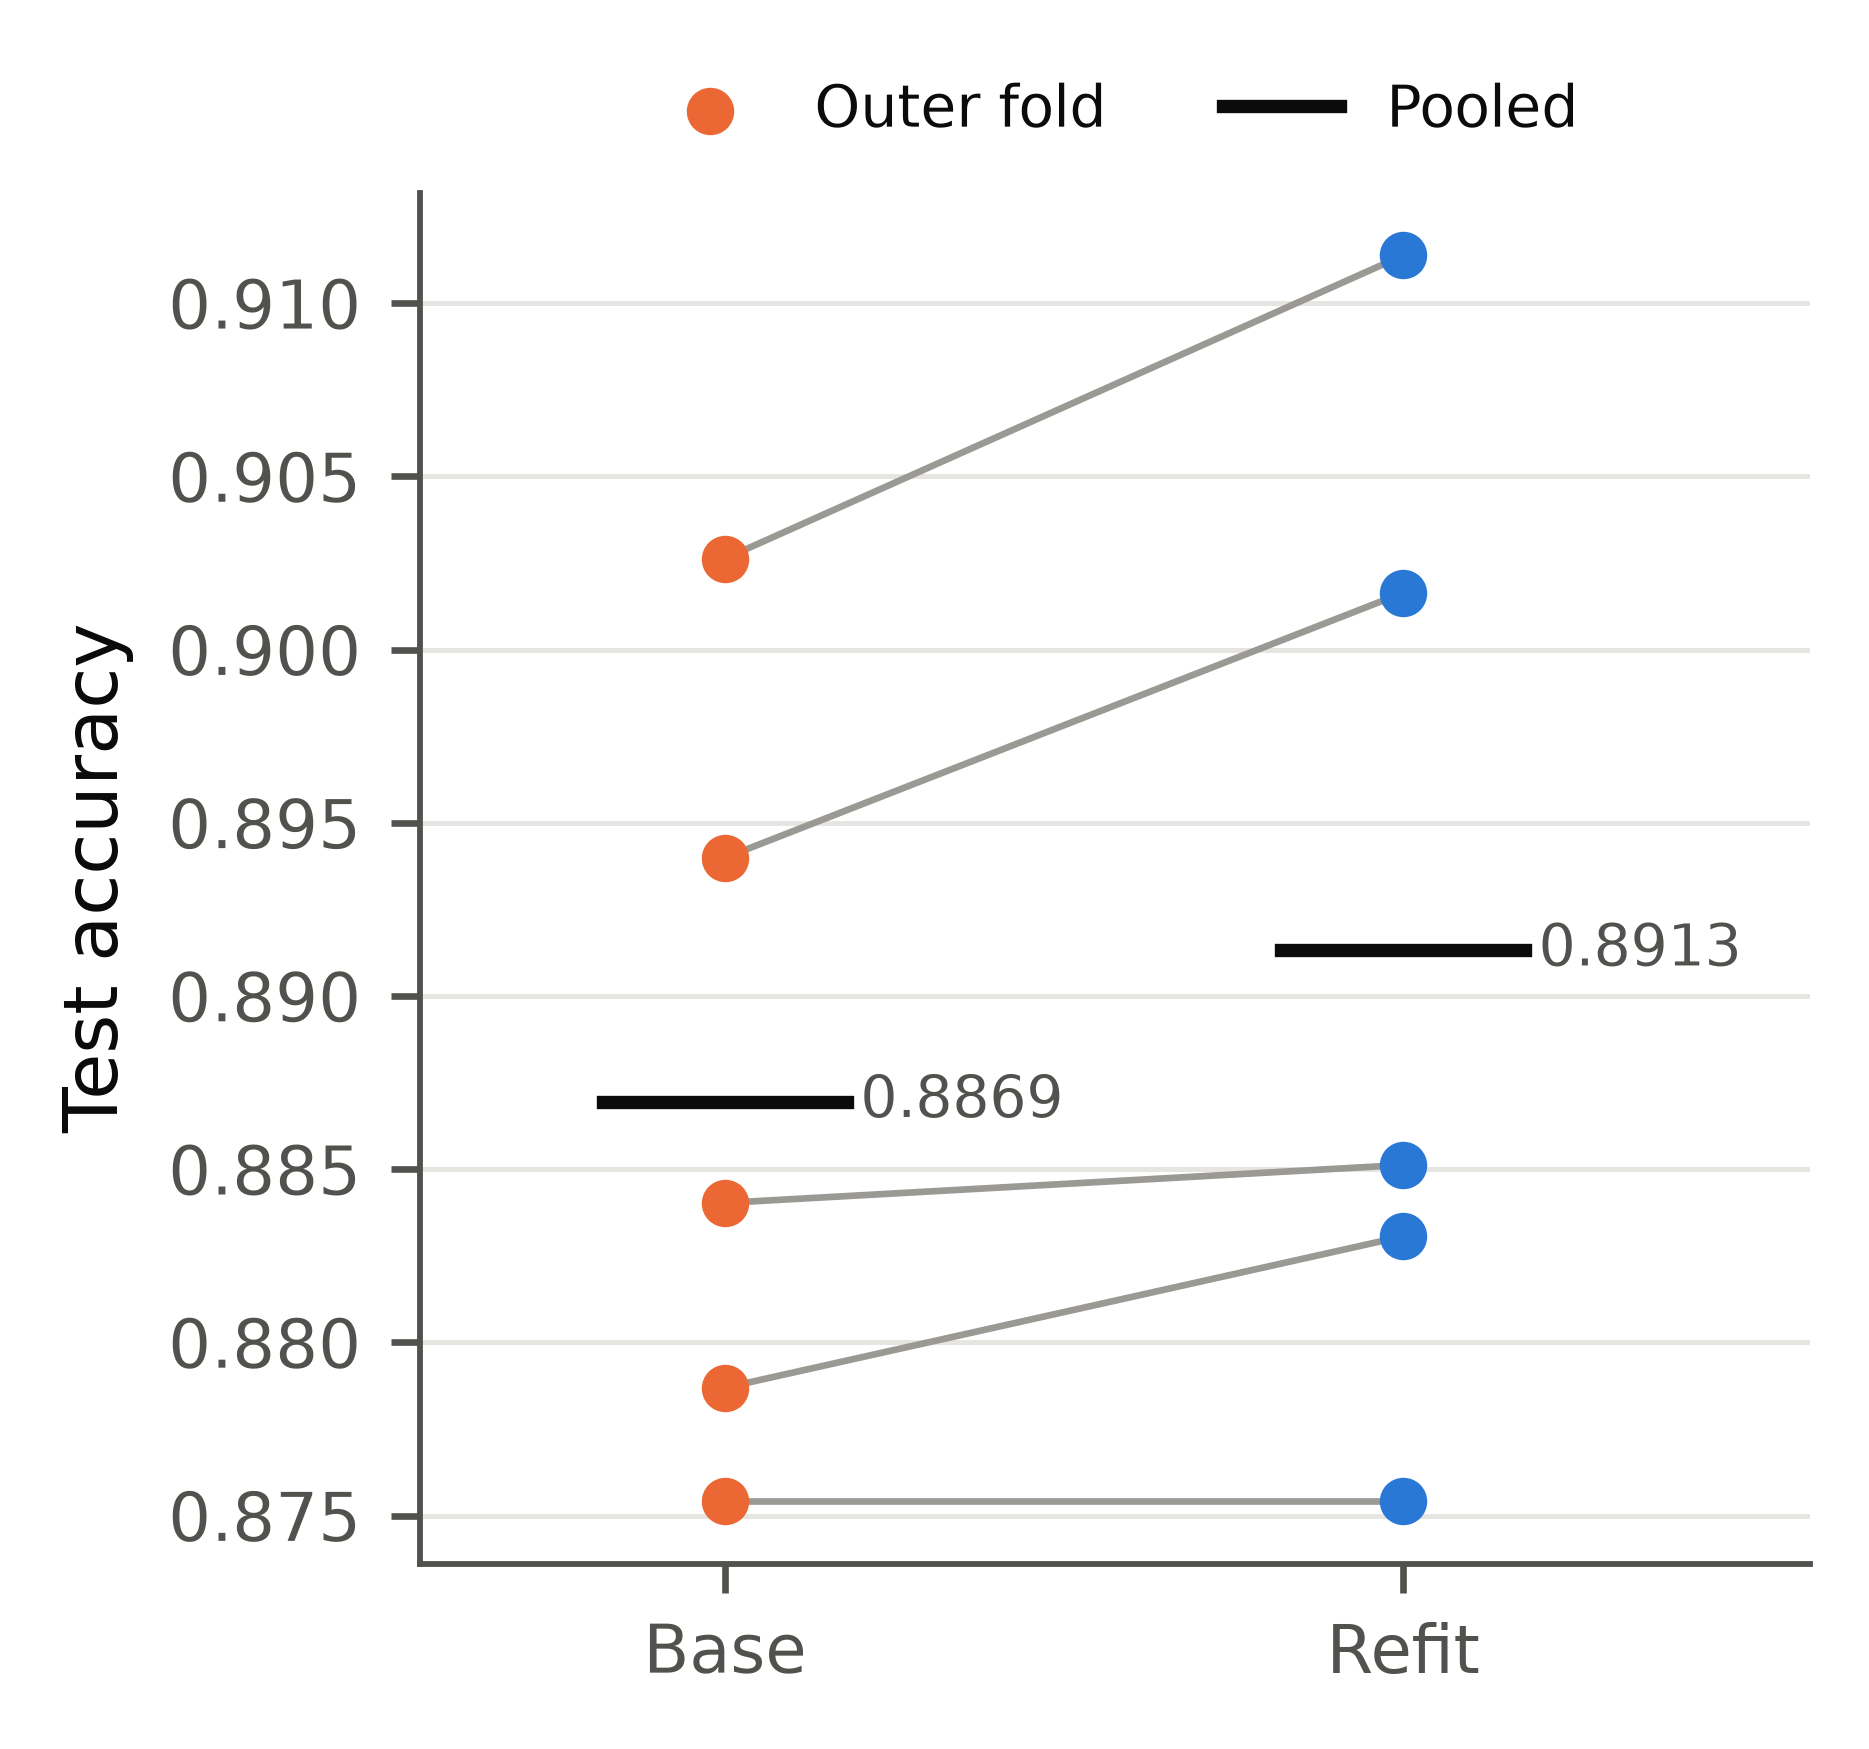

**learning_curves_all_folds** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/figures/learning_curves_all_folds.png`  
Base run of every outer fold (k=5): training objective, EMA of the tune log loss and the selected checkpoint (lowest EMA tune loss after epoch 8). The refit replays each fold's selected epoch count.

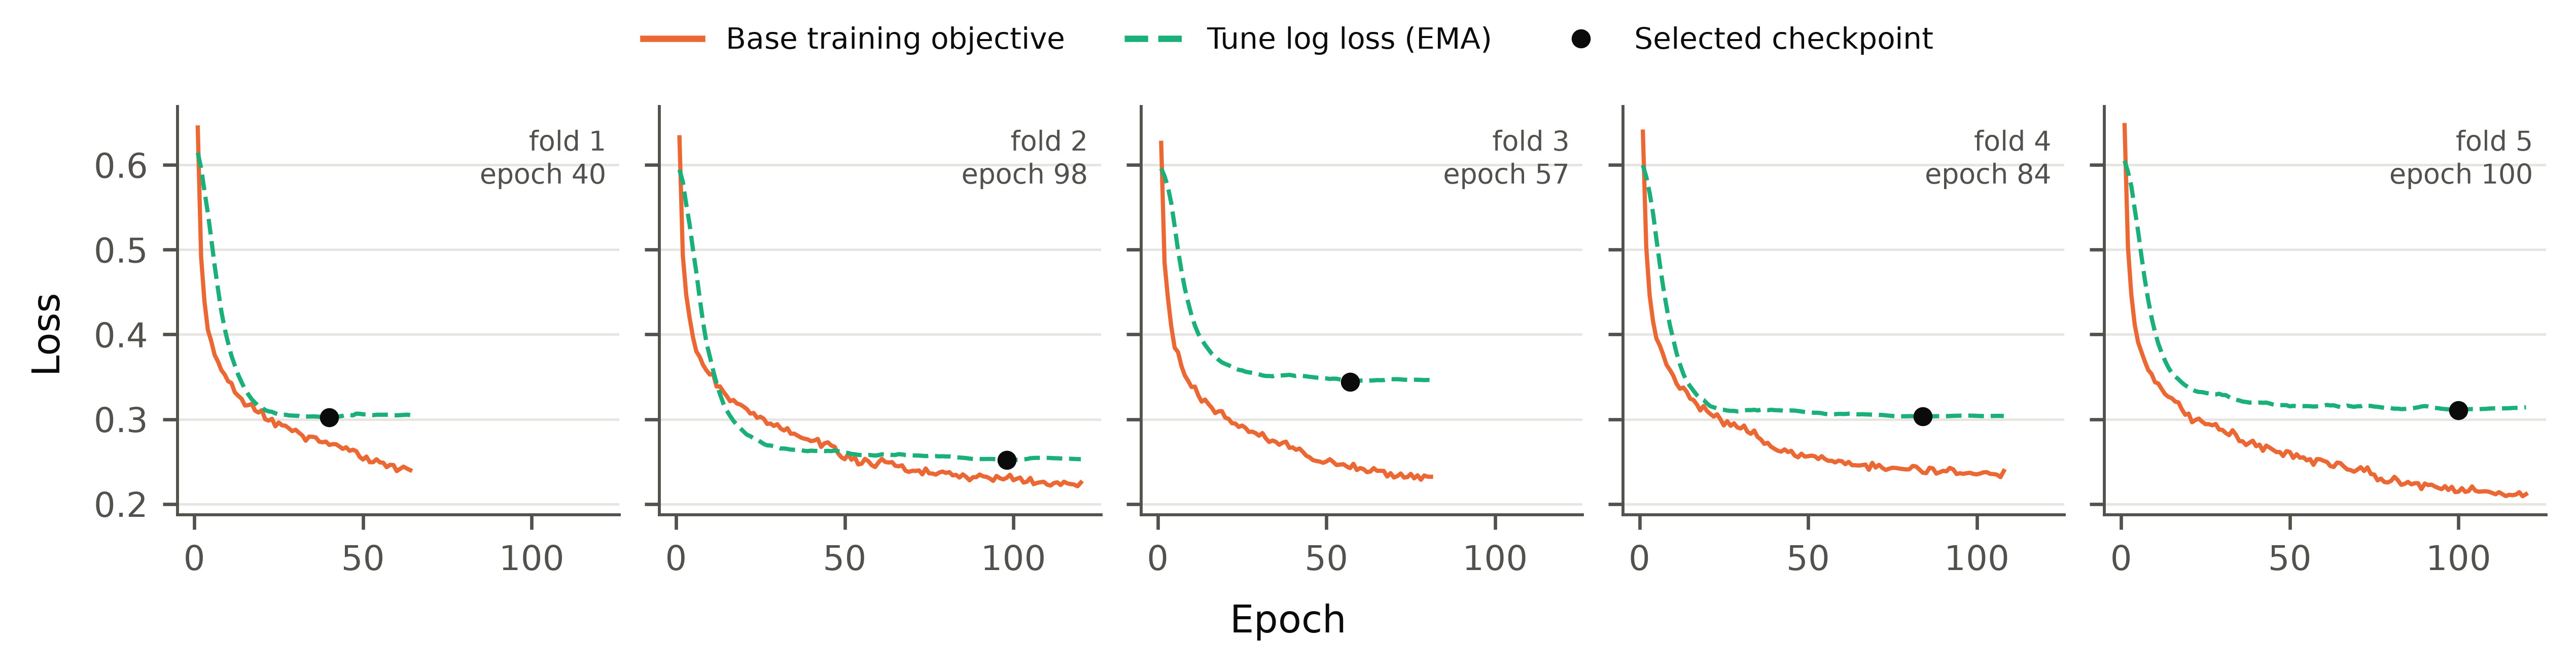

**best_epochs** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/pooled/figures/best_epochs.png`  
Selected base epoch per outer fold (k=5); 0 of 5 folds reached the 120-epoch cap (a fold at the cap was still improving when training stopped).

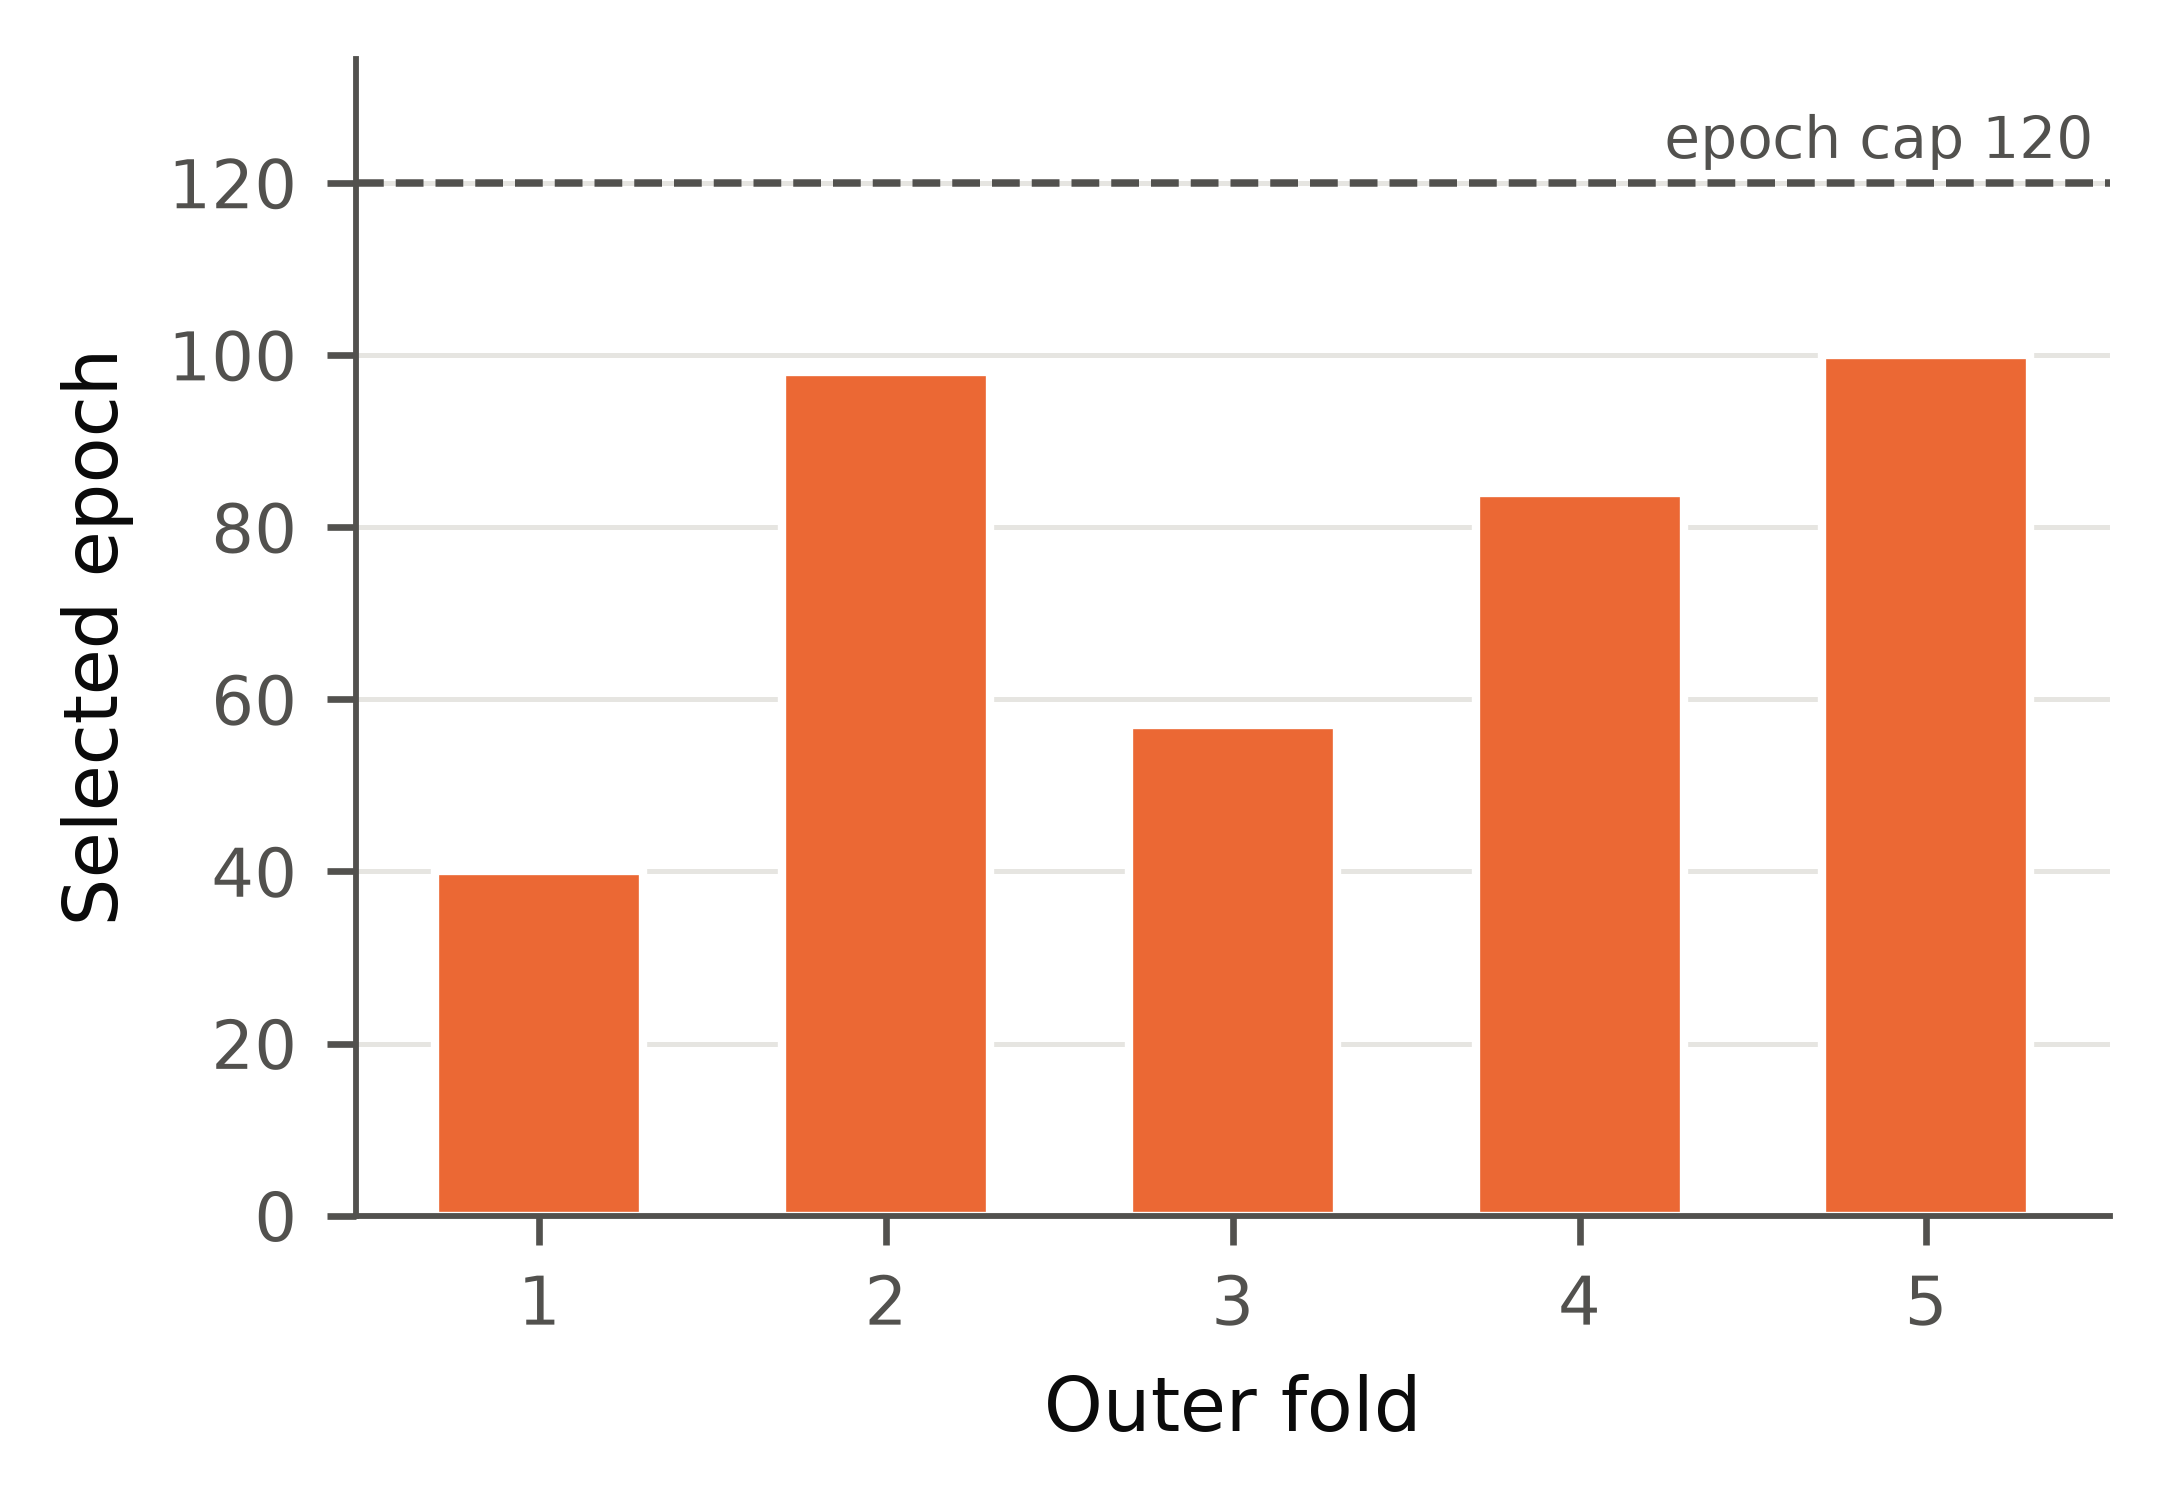

In [8]:
for name in ("roc_pr_base_vs_refit", "fold_accuracy_base_vs_refit", "learning_curves_all_folds", "best_epochs"):
    show(POOLED / "figures" / f"{name}.png")

### One fold

**learning_curves** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/fold_01/figures/learning_curves.png`  
Fold 1: base run (fit rows, checkpoint chosen on tune rows) and refit (fit + tune rows, base epochs and learning rates replayed). Dotted line: selected base epoch (40). The training objective includes label smoothing, RC-consistency and R-Drop terms, so it is not on the scale of the tune log loss; training accuracy with dropout on is below the eval-mode points.

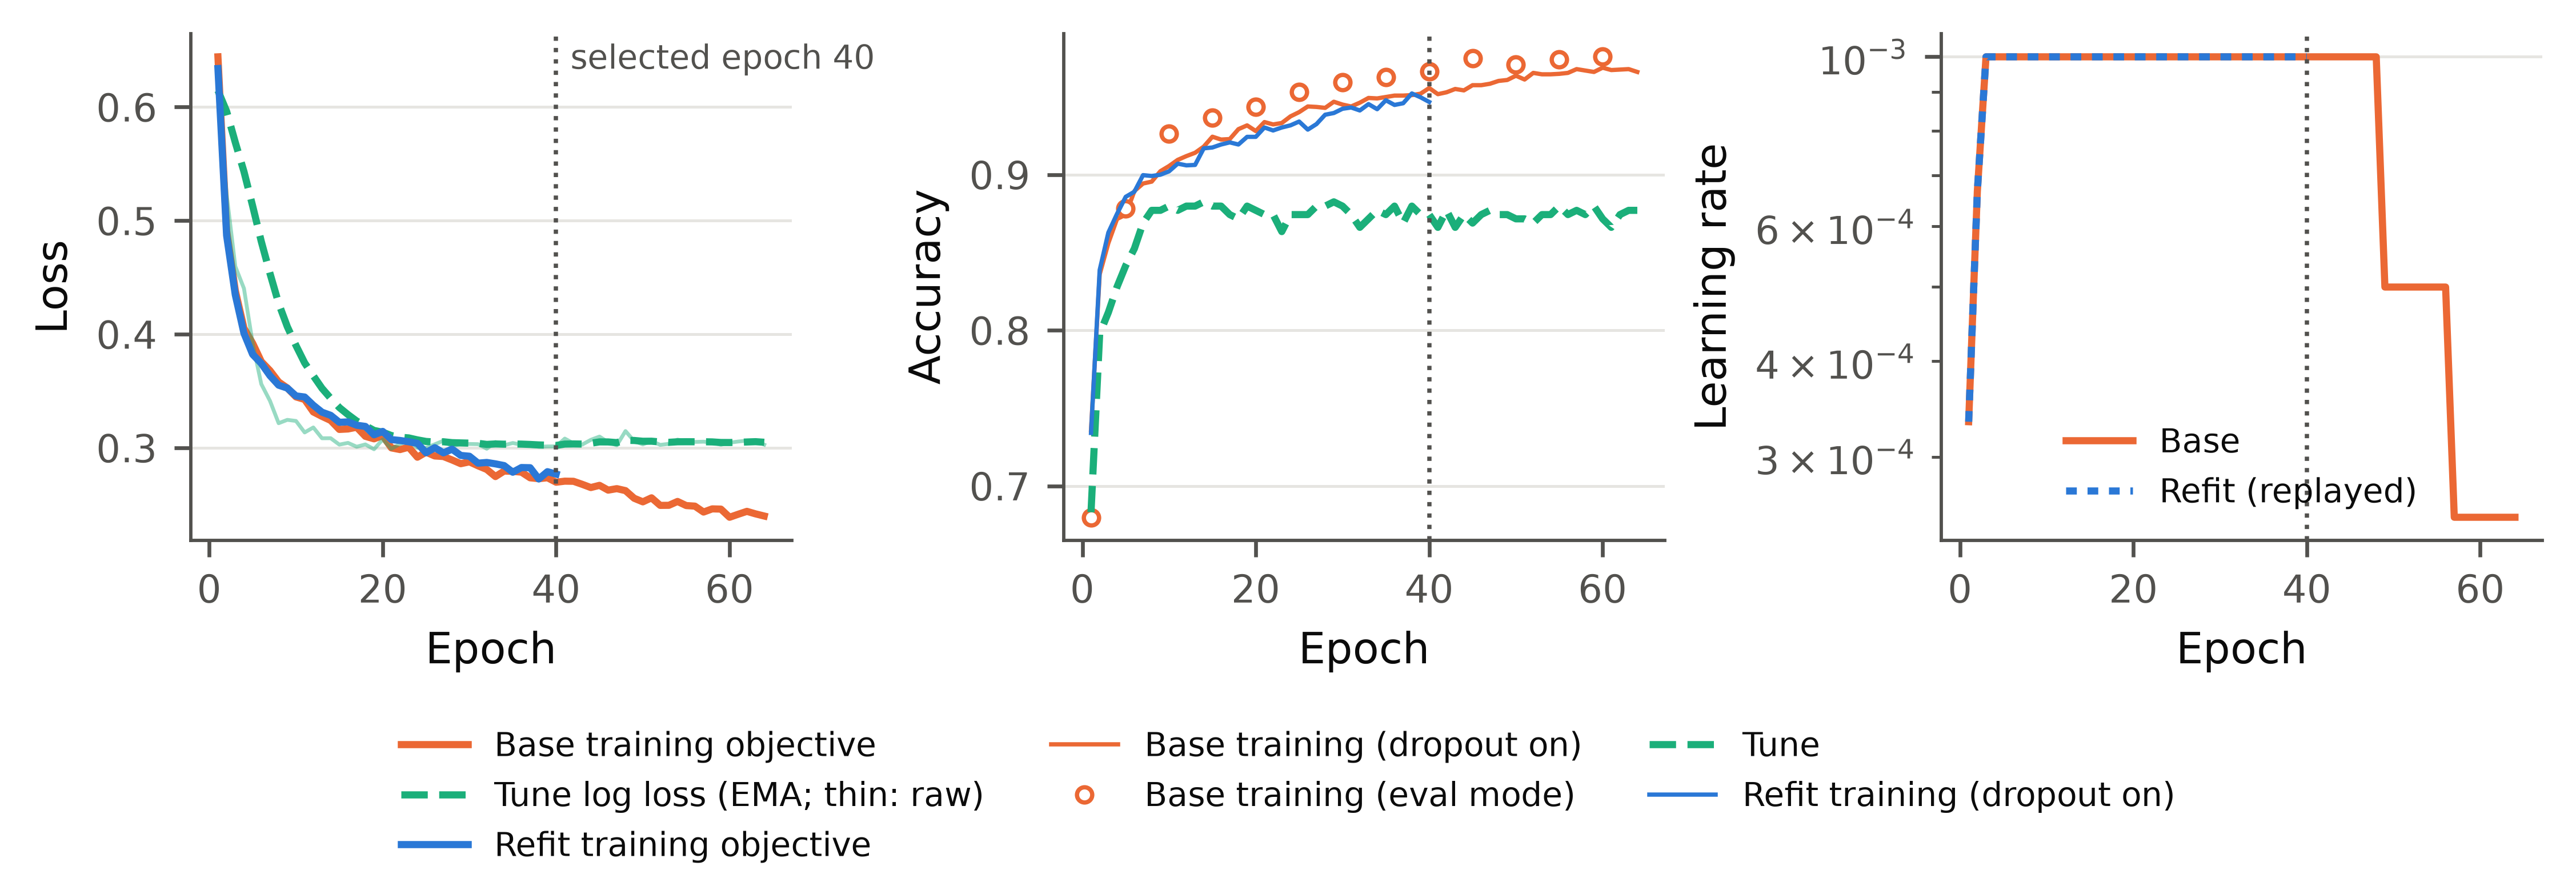

**confusion_matrix** — `results/DatasetNup_1/Homo_sapiens/k5/full/seed_151000/fold_01/figures/confusion_matrix.png`  
Fold 1, outer test rows: confusion matrices at threshold 0.5 (counts; percentages within the observed class).

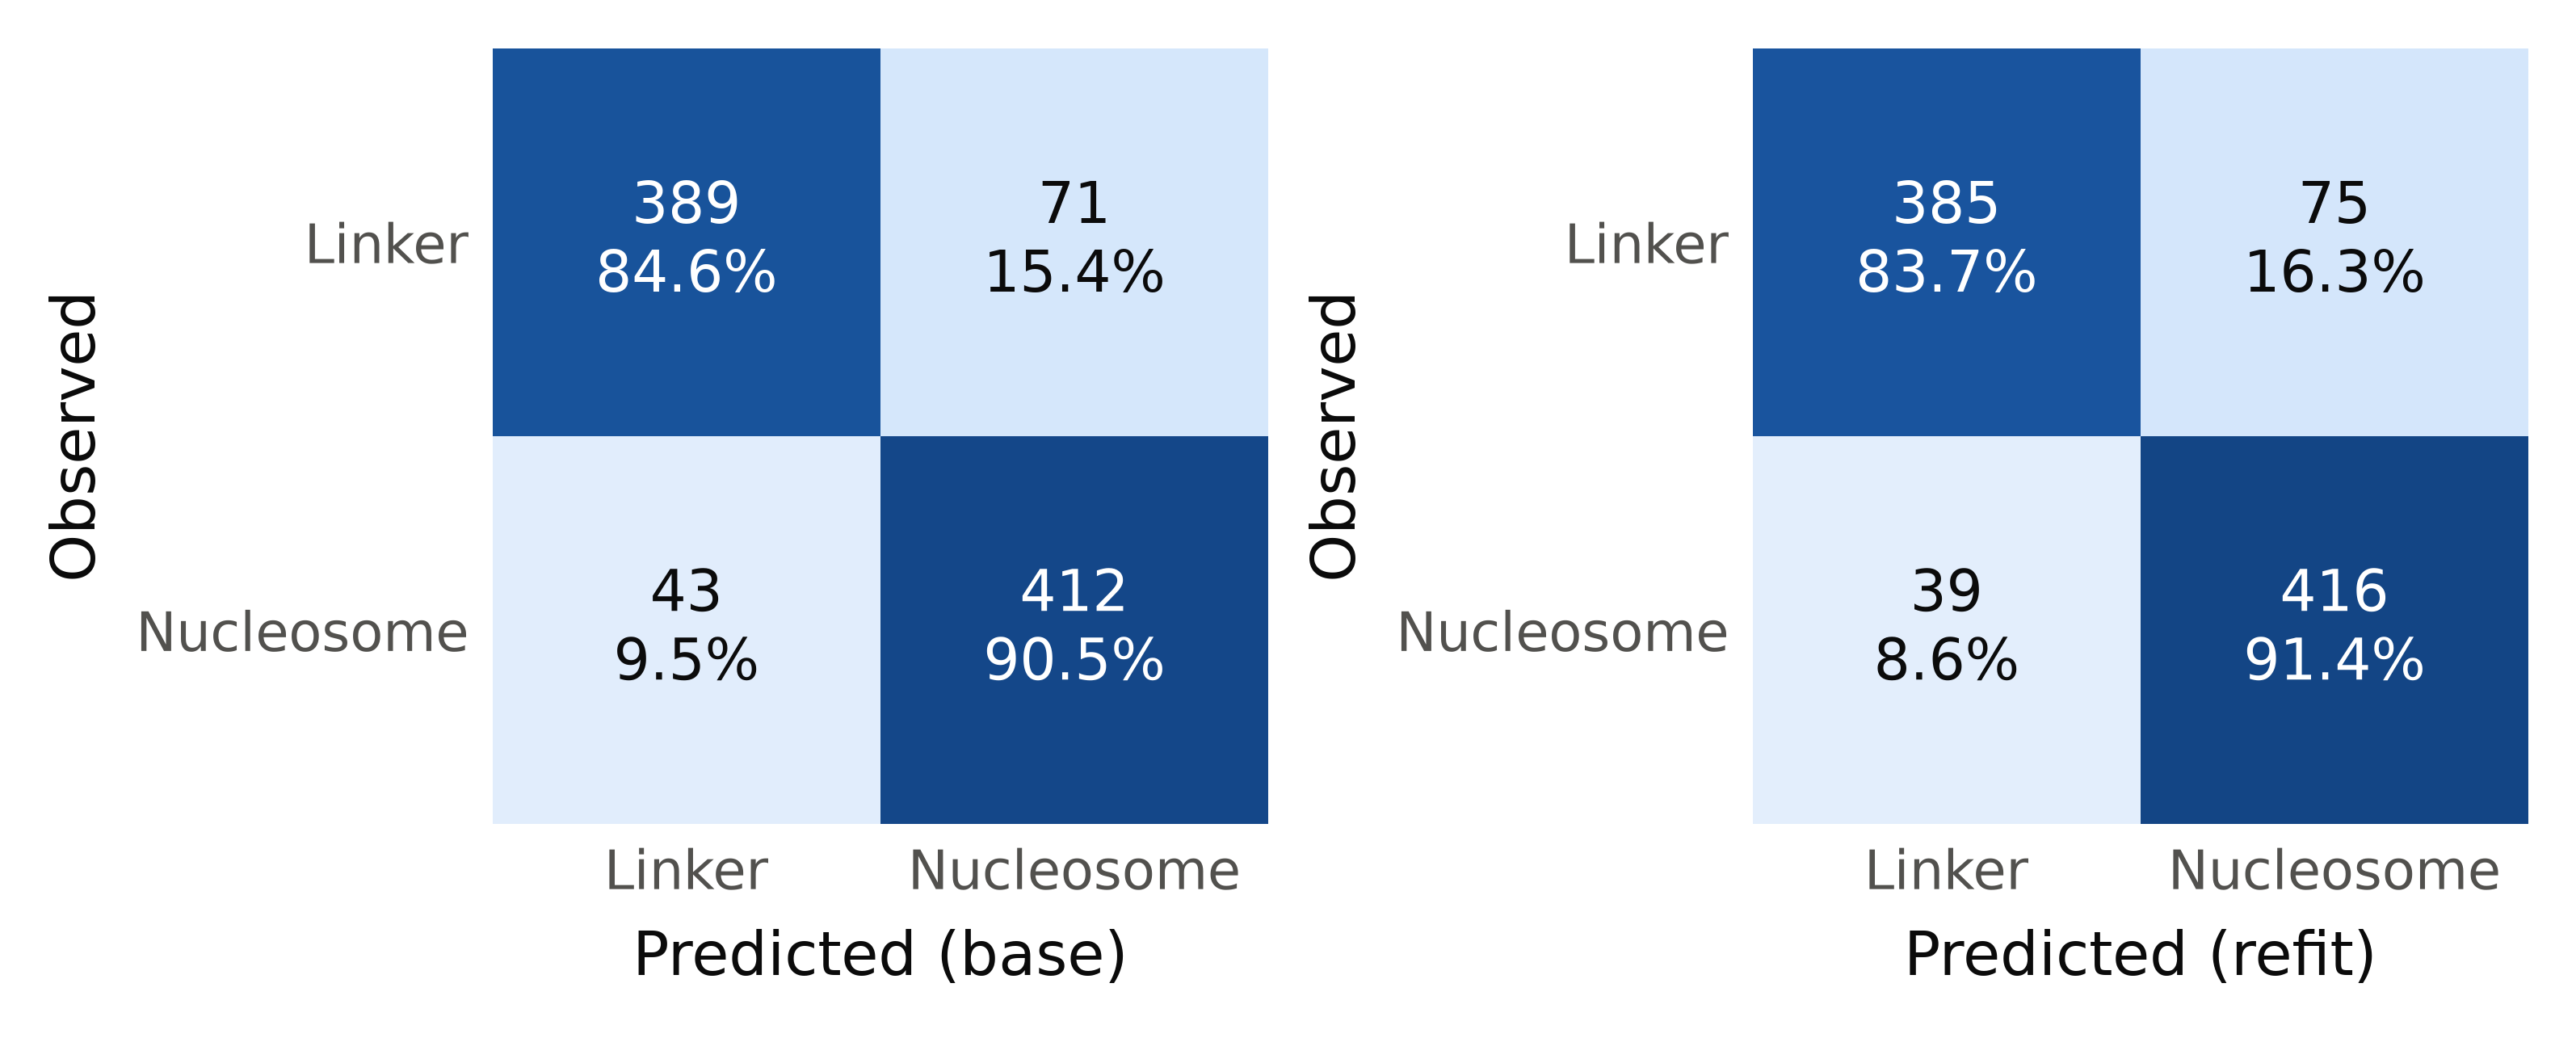

In [9]:
SHOW_FOLD = 1
FOLD = RUN / f"seed_{SHOW_SEED}" / f"fold_{SHOW_FOLD:02d}" / "figures"
for name in ("learning_curves", "confusion_matrix"):
    show(FOLD / f"{name}.png")

### Every figure of this run (PNG 600 dpi + PDF + CSV of the plotted values)

In [10]:
cat = figures.catalog(RUN)
print(len(cat), "figures")
display(cat[["folder", "figure", "suggested_caption"]].head(60))

137 figures


,folder,figure,suggested_caption
0,explain/seed_151000/figures,shap_overview,Group Shapley importance at three resolutions ...
1,explain/seed_151000/figures,shap_modality,Exact group Shapley values of the reported nuc...
2,explain/seed_151000/figures,shap_tracks,Exact group Shapley values of the reported nuc...
3,explain/seed_151000/figures,shap_channels,Exact group Shapley values of the reported nuc...
4,explain/seed_151000/figures,shap_beeswarm_tracks,"SHAP summary plot, shape tracks (pls block as ..."
5,explain/seed_151000/figures,shap_beeswarm_channels,"SHAP summary plot, shape channels level: one d..."
6,explain/seed_151000/figures,shap_dependence_tracks,"SHAP dependence, tracks level: each player's S..."
7,explain/seed_151000/figures,shap_distribution_tracks,Group Shapley value of every explained test se...
8,explain/seed_151000/figures,shap_by_outcome_tracks,Mean group Shapley value per player by predict...
9,explain/seed_151000/figures,shap_interactions_tracks,Pairwise Shapley interaction index between pla...
